# Clasificación multiclase de animales con Animals-10

**Proyecto final de aprendizaje supervisado**

Roberto Narváez

Este estudio compara regresión logística y máquinas de vectores de soporte (SVM) para clasificar imágenes de diez animales. Ambas técnicas utilizarán características visuales extraídas por MobileNetV2 preentrenada y congelada.

**Pregunta de investigación:** ¿existe una diferencia estadísticamente significativa entre el rendimiento de ambos modelos, medido con macro F1 sobre los mismos folds?

El conjunto de prueba se reservará antes de optimizar los modelos y se usará únicamente para la evaluación final. La exploración, el entrenamiento y las conclusiones se añadirán por etapas.

## Plan experimental

1. Preparación del entorno y reproducibilidad.
2. Exploración, control de calidad, duplicados y partición estratificada.
3. Preprocesamiento y extracción de embeddings con MobileNetV2.
4. Pipelines, búsqueda de hiperparámetros y curvas de aprendizaje.
5. Comparación estadística pareada de los modelos.
6. Evaluación final, t-SNE y análisis de errores.
7. Conclusiones, referencias y revisión de reproducibilidad.

Cada etapa se incorporará después de su autorización. Las decisiones y los resultados se explicarán también en `explicaciones.md`.

## Etapa 1. Entorno y datos disponibles

Ejecuta este notebook desde la raíz del proyecto, donde se encuentran las carpetas `data/` y `conf/`. En Google Colab, sitúa primero el directorio de trabajo en esa carpeta y asegúrate de que las imágenes estén disponibles en `data/`. No se necesitan credenciales de Kaggle para utilizar los datos locales.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import platform
import random
import sys

import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / 'data'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'

def package_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        if package_name == 'tensorflow':
            try:
                return version('tensorflow-cpu') + ' (CPU)'
            except PackageNotFoundError:
                pass
        return 'no instalado'

print(f'Python: {sys.version.split()[0]} | Sistema: {platform.platform()}')
print(f'Semilla: {SEED}')
print(f'Raíz del proyecto: {PROJECT_ROOT}')
for package in ('numpy', 'pandas', 'scikit-learn', 'tensorflow', 'Pillow', 'matplotlib'):
    print(f'{package}: {package_version(package)}')

Python: 3.12.10 | Sistema: Windows-11-10.0.26300-SP0
Semilla: 42
Raíz del proyecto: C:\Users\rober\Documents\USFQ_IA\4_Aprendizaje Supervisado\Tareas\ProyectoFinal
numpy: 2.5.5
pandas: 3.0.5
scikit-learn: 1.9.0
tensorflow: 2.21.0 (CPU)
Pillow: 12.3.0
matplotlib: 3.11.1


### Verificación de la estructura

Las etiquetas originales de Animals-10 están en italiano. Se conserva el nombre de cada carpeta como identificador estable y se ofrece una traducción al español para las figuras y explicaciones. Esta celda comprueba las diez carpetas sin leer imágenes ni crear una partición de datos.

In [2]:
CLASS_NAMES_ES = {
    'cane': 'perro',
    'cavallo': 'caballo',
    'elefante': 'elefante',
    'farfalla': 'mariposa',
    'gallina': 'gallina',
    'gatto': 'gato',
    'mucca': 'vaca',
    'pecora': 'oveja',
    'ragno': 'araña',
    'scoiattolo': 'ardilla',
}
CLASS_NAMES = tuple(CLASS_NAMES_ES)
missing_classes = [name for name in CLASS_NAMES if not (DATA_DIR / name).is_dir()]
if missing_classes:
    raise FileNotFoundError(
        f'Faltan carpetas en {DATA_DIR}: {missing_classes}. '
        'Ubica Animals-10 en data/ y ejecuta el notebook desde la raíz del proyecto.'
    )
print(f'Datos disponibles: {DATA_DIR}')
print(f'Clases verificadas: {len(CLASS_NAMES)}')
print(', '.join(f'{original} -> {espanol}' for original, espanol in CLASS_NAMES_ES.items()))

Datos disponibles: C:\Users\rober\Documents\USFQ_IA\4_Aprendizaje Supervisado\Tareas\ProyectoFinal\data
Clases verificadas: 10
cane -> perro, cavallo -> caballo, elefante -> elefante, farfalla -> mariposa, gallina -> gallina, gatto -> gato, mucca -> vaca, pecora -> oveja, ragno -> araña, scoiattolo -> ardilla


**Estado:** la etapa 1 termina al comprobar el entorno y las rutas. La siguiente etapa realizará el análisis exploratorio y definirá la partición experimental; aún no hay métricas ni conclusiones de modelos.

## Etapa 2. Exploración, calidad y partición

Se inspeccionan todos los archivos de las diez clases antes de dividir los datos. El inventario registra dimensiones, formato, modo de color, medias RGB y hashes. Los archivos ilegibles se excluyen y quedan documentados. La exploración describe el conjunto disponible; no se utiliza el test para elegir hiperparámetros.

In [3]:
import hashlib
import json

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageOps, UnidentifiedImageError

IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
DUPLICATE_DISTANCE = 3  # distancia de Hamming máxima entre hashes perceptuales de 64 bits
MANUAL_EXCLUSIONS = {
    'data/mucca/OIP-G725phaTAmA_QdNdnqIWTwHaE8.jpeg': 'etiqueta incorrecta: caballo en carpeta vaca',
}
records, incidents = [], []
rgb_hist = np.zeros((3, 32), dtype=np.int64)

def difference_hash(rgb_image):
    gray = rgb_image.convert('L').resize((9, 8), Image.Resampling.LANCZOS)
    pixels = np.asarray(gray, dtype=np.uint8)
    bits = (pixels[:, 1:] > pixels[:, :-1]).reshape(-1)
    return int(''.join('1' if bit else '0' for bit in bits), 2)

for class_name in CLASS_NAMES:
    paths = sorted(p for p in (DATA_DIR / class_name).iterdir() if p.is_file())
    for path in paths:
        relative_path = path.relative_to(PROJECT_ROOT).as_posix()
        if relative_path in MANUAL_EXCLUSIONS:
            incidents.append({'relative_path': relative_path, 'reason': MANUAL_EXCLUSIONS[relative_path]})
            continue
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            incidents.append({'relative_path': relative_path, 'reason': 'extensión no admitida'})
            continue
        try:
            file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
            with Image.open(path) as image:
                image.load()
                width, height = image.size
                image_format, image_mode = image.format, image.mode
                rgb = ImageOps.exif_transpose(image).convert('RGB')
                thumbnail = np.asarray(rgb.resize((32, 32), Image.Resampling.BILINEAR))
                if thumbnail.std() < 2:
                    incidents.append({'relative_path': relative_path, 'reason': 'imagen casi uniforme'})
                    continue
                means = thumbnail.mean(axis=(0, 1))
                perceptual_hash = difference_hash(rgb)
            for channel in range(3):
                rgb_hist[channel] += np.bincount(
                    (thumbnail[:, :, channel] // 8).reshape(-1), minlength=32
                )
            records.append({
                'relative_path': relative_path, 'class_name': class_name,
                'class_es': CLASS_NAMES_ES[class_name], 'width': width, 'height': height,
                'aspect_ratio': width / height, 'format': image_format, 'mode': image_mode,
                'mean_r': means[0], 'mean_g': means[1], 'mean_b': means[2],
                'mean_intensity': means.mean(), 'sha256': file_hash,
                'dhash': f'{perceptual_hash:016x}',
            })
        except (OSError, ValueError, UnidentifiedImageError, Image.DecompressionBombError) as exc:
            incidents.append({'relative_path': relative_path, 'reason': type(exc).__name__})
    print(f'{class_name}: {sum(r["class_name"] == class_name for r in records)} imágenes válidas')

inventory = pd.DataFrame.from_records(records)
if inventory.empty or inventory['class_name'].nunique() != len(CLASS_NAMES):
    raise ValueError('El inventario no contiene imágenes válidas de las diez clases.')
incidents_df = pd.DataFrame.from_records(incidents, columns=['relative_path', 'reason'])
print(f'Total válido: {len(inventory)} | Incidencias: {len(incidents_df)}')
display(inventory.groupby(['class_name', 'class_es']).agg(
    images=('relative_path', 'size'), width_median=('width', 'median'),
    height_median=('height', 'median'), intensity_mean=('mean_intensity', 'mean')
).round(2))
display(inventory[['width', 'height', 'aspect_ratio']].describe().round(2))
display(inventory.groupby(['format', 'mode']).size().rename('images').reset_index())
display(incidents_df.head(20))

cane: 4863 imágenes válidas


cavallo: 2623 imágenes válidas


elefante: 1446 imágenes válidas


farfalla: 2111 imágenes válidas


gallina: 3098 imágenes válidas


gatto: 1668 imágenes válidas


... (4 outputs left out)

,,images,width_median,height_median,intensity_mean
class_name,class_es,,,,
cane,perro,4863,300.0,225.0,125.24
cavallo,caballo,2623,300.0,225.0,119.91
elefante,elefante,1446,300.0,225.0,121.01
farfalla,mariposa,2111,300.0,230.0,118.44
gallina,gallina,3098,300.0,225.0,117.61
gatto,gato,1668,300.0,243.5,125.50
mucca,vaca,1865,300.0,209.0,116.87
pecora,oveja,1820,300.0,225.0,115.16
ragno,araña,4821,300.0,225.0,129.14


,width,height,aspect_ratio
count,26177.00,26177.00,26177.00
mean,320.03,252.63,1.31
std,196.93,148.41,0.31
min,60.00,57.00,0.29
25%,300.00,200.00,1.14
50%,300.00,225.00,1.33
75%,300.00,300.00,1.50
max,6720.00,6000.00,4.23


,format,mode,images
0,JPEG,CMYK,1
1,JPEG,L,1
2,JPEG,RGB,26125
3,PNG,RGB,2
4,PNG,RGBA,48


,relative_path,reason
0,data/farfalla/eb35b30729f1073ed1584d05fb1d4e9f...,imagen casi uniforme
1,data/mucca/OIP-G725phaTAmA_QdNdnqIWTwHaE8.jpeg,etiqueta incorrecta: caballo en carpeta vaca


### Balance, resolución, color y ejemplos

Las barras permiten detectar desbalance entre clases. Las distribuciones de resolución y aspecto revelan imágenes atípicas. El histograma RGB se calcula sobre miniaturas de 32 × 32 píxeles: resume el color del conjunto con menor costo, pero no representa cada píxel original. Se muestran dos imágenes elegidas con semilla fija por clase.

,images,percent
class_es,,
perro,4863,18.58
araña,4821,18.42
gallina,3098,11.83
caballo,2623,10.02
mariposa,2111,8.06
vaca,1865,7.12
ardilla,1862,7.11
oveja,1820,6.95
gato,1668,6.37


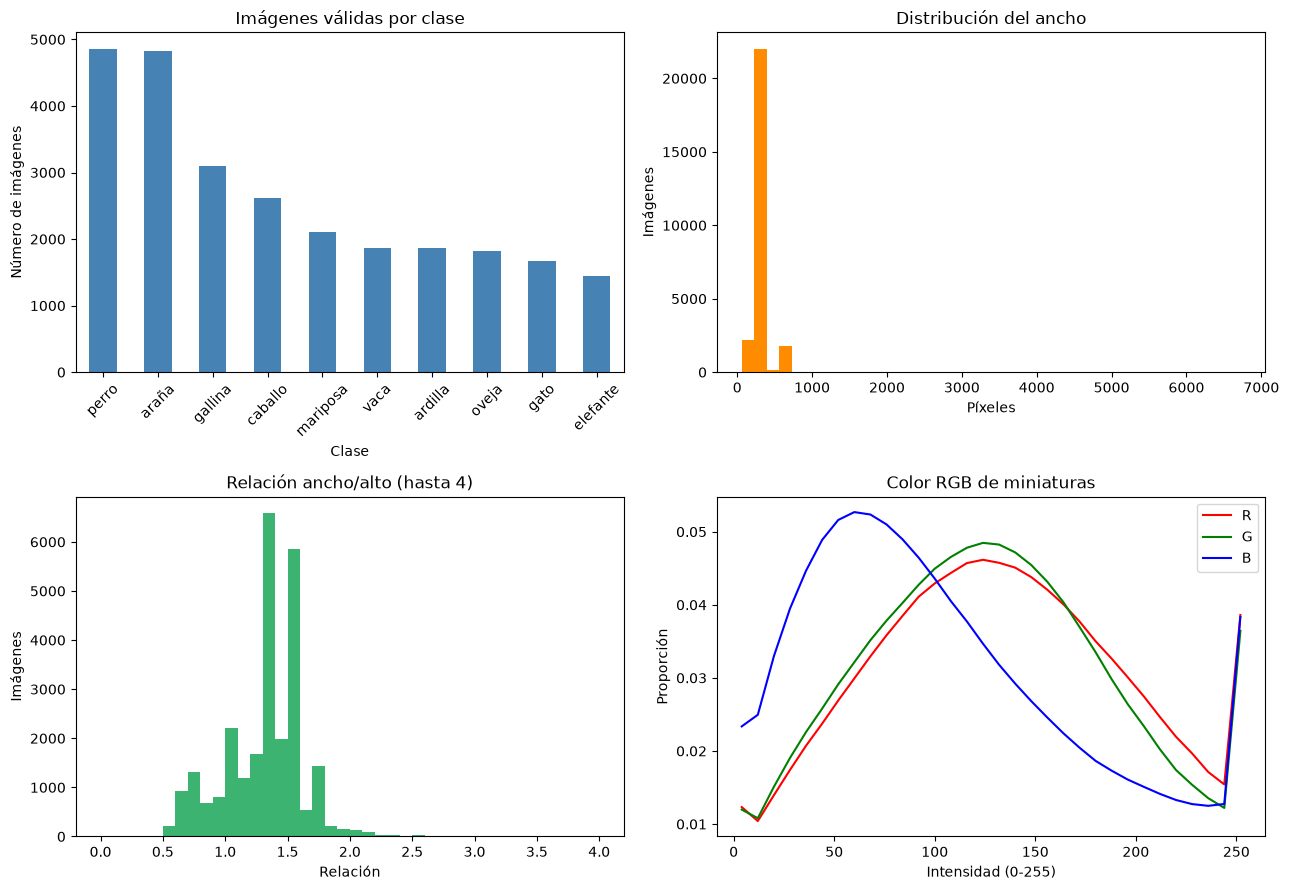

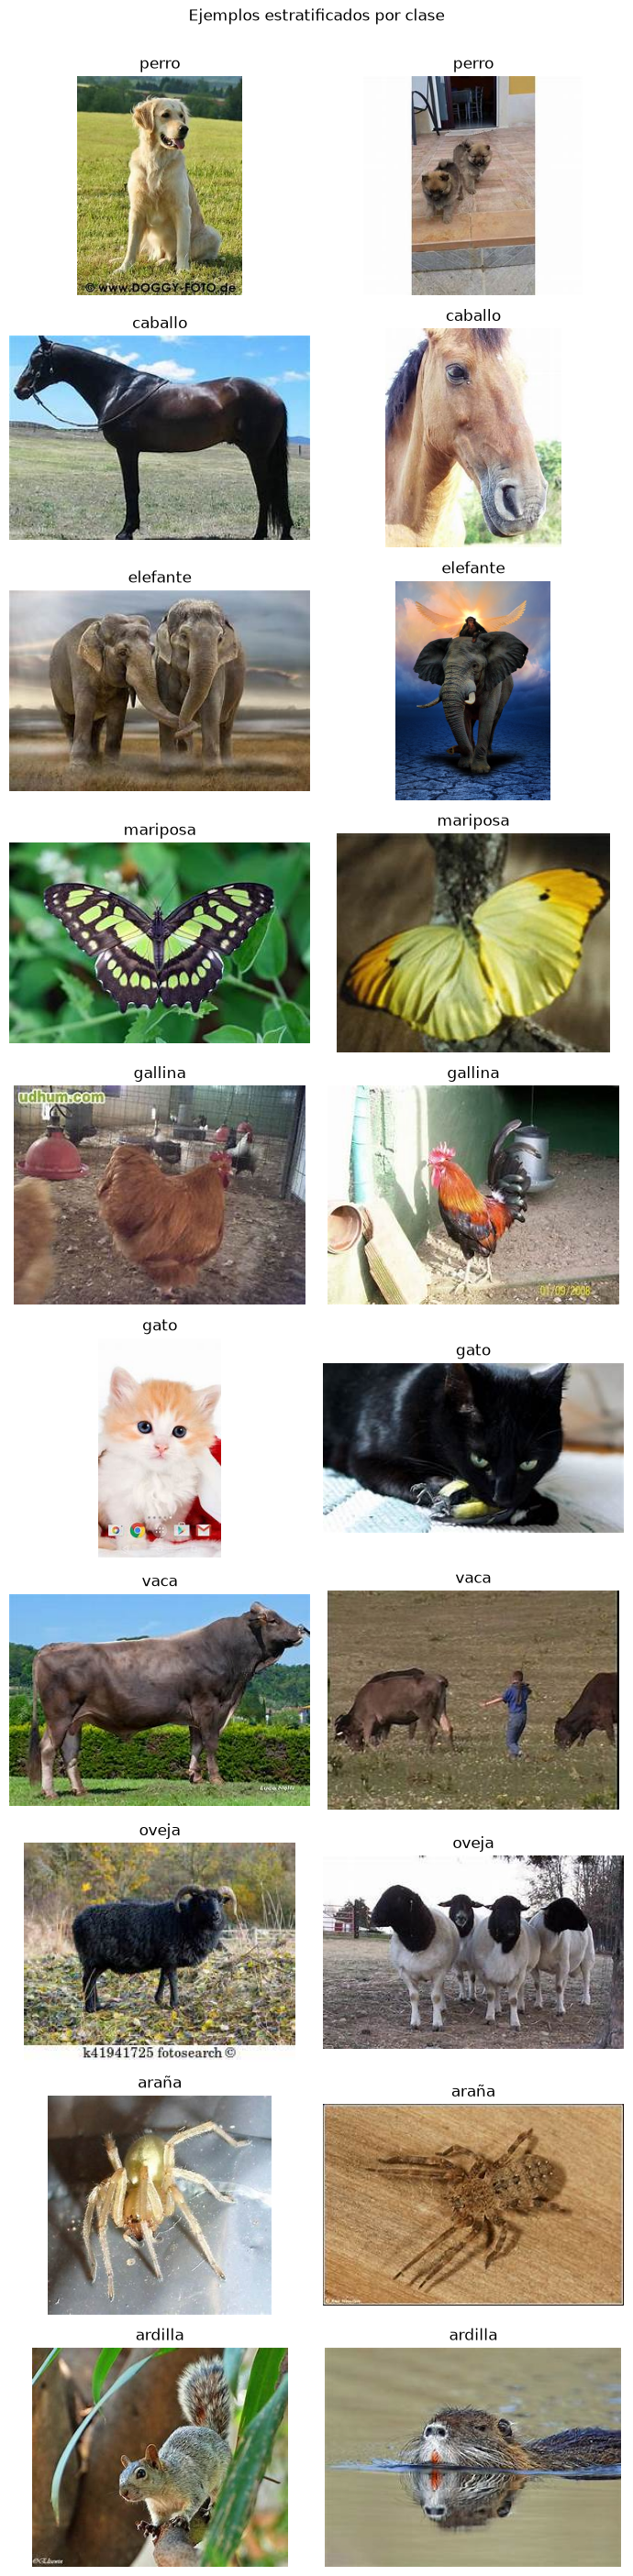

In [4]:
class_counts = inventory.groupby('class_es').size().sort_values(ascending=False)
class_table = class_counts.to_frame('images')
class_table['percent'] = (100 * class_table['images'] / len(inventory)).round(2)
display(class_table)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
class_counts.plot.bar(ax=axes[0, 0], color='steelblue')
axes[0, 0].set(title='Imágenes válidas por clase', xlabel='Clase', ylabel='Número de imágenes')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 1].hist(inventory['width'], bins=40, color='darkorange')
axes[0, 1].set(title='Distribución del ancho', xlabel='Píxeles', ylabel='Imágenes')
axes[1, 0].hist(inventory['aspect_ratio'], bins=40, range=(0, 4), color='mediumseagreen')
axes[1, 0].set(title='Relación ancho/alto (hasta 4)', xlabel='Relación', ylabel='Imágenes')
bin_centers = np.arange(32) * 8 + 4
for channel, color, name in zip(range(3), ('red', 'green', 'blue'), ('R', 'G', 'B')):
    axes[1, 1].plot(bin_centers, rgb_hist[channel] / rgb_hist[channel].sum(), color=color, label=name)
axes[1, 1].set(title='Color RGB de miniaturas', xlabel='Intensidad (0-255)', ylabel='Proporción')
axes[1, 1].legend()
fig.tight_layout()
plt.show()

examples = (inventory.groupby('class_name', group_keys=False)
            .apply(lambda group: group.sample(n=min(2, len(group)), random_state=SEED),
                   include_groups=False).reset_index(drop=True))
fig, axes = plt.subplots(10, 2, figsize=(7, 28))
for row, class_name in enumerate(CLASS_NAMES):
    selected = examples[examples['relative_path'].str.startswith(f'data/{class_name}/')]
    for col, (_, item) in enumerate(selected.iterrows()):
        with Image.open(PROJECT_ROOT / item['relative_path']) as image:
            axes[row, col].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row, col].set_title(CLASS_NAMES_ES[class_name])
        axes[row, col].axis('off')
fig.suptitle('Ejemplos estratificados por clase', y=1.002)
fig.tight_layout()
plt.show()

### Duplicados y grupos de imágenes similares

SHA-256 detecta archivos idénticos. Un dHash de 64 bits, comparado con distancia de Hamming máxima de 3, identifica candidatos visualmente similares aunque el archivo cambie de tamaño o compresión. Se unen transitivamente los candidatos en grupos; cada grupo irá íntegro a desarrollo o test. dHash es una aproximación y puede agrupar imágenes distintas: se informa el tamaño de los grupos y los conflictos entre etiquetas para revisión.

In [5]:
class BKNode:
    def __init__(self, value, index):
        self.value, self.indices, self.children = value, [index], {}

    def add(self, value, index):
        node = self
        while True:
            distance = (value ^ node.value).bit_count()
            if distance == 0:
                node.indices.append(index)
                return
            if distance not in node.children:
                node.children[distance] = BKNode(value, index)
                return
            node = node.children[distance]

    def search(self, value, radius):
        matches, stack = [], [self]
        while stack:
            node = stack.pop()
            distance = (value ^ node.value).bit_count()
            if distance <= radius:
                matches.extend(node.indices)
            stack.extend(child for edge, child in node.children.items()
                         if distance - radius <= edge <= distance + radius)
        return matches

parent = list(range(len(inventory)))
def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(left, right):
    root_left, root_right = find(left), find(right)
    if root_left != root_right:
        parent[max(root_left, root_right)] = min(root_left, root_right)

for indices in inventory.groupby('sha256').indices.values():
    for index in indices[1:]:
        union(int(indices[0]), int(index))

tree = None
for index, value in enumerate(inventory['dhash']):
    hash_int = int(value, 16)
    if tree is None:
        tree = BKNode(hash_int, index)
    else:
        for match in tree.search(hash_int, DUPLICATE_DISTANCE):
            union(index, match)
        tree.add(hash_int, index)

roots = [find(i) for i in range(len(inventory))]
root_to_group = {root: group for group, root in enumerate(sorted(set(roots)))}
inventory['group_id'] = [root_to_group[root] for root in roots]
group_sizes = inventory.groupby('group_id').size()
mixed_groups = inventory.groupby('group_id')['class_name'].nunique()
print(f'Archivos SHA-256 repetidos: {len(inventory) - inventory["sha256"].nunique()}')
print(f'Grupos de similitud con más de una imagen: {(group_sizes > 1).sum()}')
print(f'Imágenes en esos grupos: {group_sizes[group_sizes > 1].sum()}')
print(f'Grupos con etiquetas distintas: {(mixed_groups > 1).sum()}')
display(group_sizes.describe().rename('tamaño del grupo'))
display(inventory[inventory['group_id'].isin(mixed_groups[mixed_groups > 1].index)]
        [['relative_path', 'class_name', 'group_id']].head(30))

Archivos SHA-256 repetidos: 0
Grupos de similitud con más de una imagen: 1127
Imágenes en esos grupos: 2513
Grupos con etiquetas distintas: 0


count    24791.000000
mean         1.055907
std          0.297936
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          9.000000
Name: tamaño del grupo, dtype: float64

,relative_path,class_name,group_id


### Partición experimental

`StratifiedGroupKFold` genera cinco particiones candidatas con grupos indivisibles. Se elige como test la que más se aproxima al 20 % y a la distribución global de clases; el resto constituye desarrollo. Se guardan rutas relativas y grupos en CSV para reutilizar exactamente la partición en las siguientes etapas. El test permanece sin usar para modelado hasta la etapa 6.

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
overall_share = inventory['class_name'].value_counts(normalize=True).reindex(CLASS_NAMES)
candidates = []
for fold, (development_idx, test_idx) in enumerate(
        splitter.split(inventory, inventory['class_name'], inventory['group_id'])):
    test_share = (inventory.iloc[test_idx]['class_name'].value_counts(normalize=True)
                  .reindex(CLASS_NAMES, fill_value=0))
    deviation = abs(len(test_idx) / len(inventory) - 0.20) + (test_share - overall_share).abs().sum()
    candidates.append((deviation, fold, development_idx, test_idx))
_, selected_fold, development_idx, test_idx = min(candidates, key=lambda item: item[0])
development_groups = set(inventory.iloc[development_idx]['group_id'])
test_groups = set(inventory.iloc[test_idx]['group_id'])
assert development_groups.isdisjoint(test_groups)
assert set(inventory.iloc[test_idx]['class_name']) == set(CLASS_NAMES)
inventory['split'] = 'development'
inventory.loc[test_idx, 'split'] = 'test'
split_table = pd.crosstab(inventory['class_es'], inventory['split'])
split_table['test_percent'] = (100 * split_table['test'] / split_table.sum(axis=1)).round(2)
print(f'Fold elegido: {selected_fold + 1} | Test: {len(test_idx) / len(inventory):.2%}')
display(split_table)

ARTIFACTS_DIR.mkdir(exist_ok=True)
inventory.to_csv(ARTIFACTS_DIR / 'inventario_imagenes.csv', index=False)
incidents_df.to_csv(ARTIFACTS_DIR / 'incidencias_eda.csv', index=False)
inventory[['relative_path', 'class_name', 'class_es', 'group_id', 'split']].to_csv(
    ARTIFACTS_DIR / 'particion.csv', index=False)
summary = {
    'seed': SEED, 'valid_images': int(len(inventory)), 'incidents': int(len(incidents_df)),
    'near_duplicate_hamming_threshold': DUPLICATE_DISTANCE,
    'similarity_groups': int(len(group_sizes)),
    'mixed_label_groups': int((mixed_groups > 1).sum()),
    'development_images': int(len(development_idx)), 'test_images': int(len(test_idx)),
    'selected_fold': int(selected_fold + 1),
}
(ARTIFACTS_DIR / 'resumen_etapa2.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Artefactos guardados en {ARTIFACTS_DIR}')

Fold elegido: 1 | Test: 20.00%


split,development,test,test_percent
class_es,,,
araña,3857,964,20.00
ardilla,1489,373,20.03
caballo,2099,524,19.98
elefante,1157,289,19.99
gallina,2478,620,20.01
gato,1334,334,20.02
mariposa,1689,422,19.99
oveja,1456,364,20.00
perro,3890,973,20.01


Artefactos guardados en C:\Users\rober\Documents\USFQ_IA\4_Aprendizaje Supervisado\Tareas\ProyectoFinal\artifacts

**Estado:** la etapa 2 termina con el inventario, las incidencias y una partición persistida. Antes de entrenar, revisa los grupos con etiquetas distintas y los archivos problemáticos. La etapa 3 usará solo los archivos válidos y la partición guardada.

## Etapa 3. Representaciones visuales con MobileNetV2

MobileNetV2 preentrenada en ImageNet se usa como extractor **congelado**, sin su clasificador final y con global average pooling. Cada imagen se convierte en un vector de 1 280 características. Esta etapa procesa únicamente el conjunto de desarrollo; el test seguirá reservado hasta la evaluación final.

Se necesita TensorFlow. En Google Colab suele estar disponible; si falta, instala `tensorflow` en el entorno antes de ejecutar estas celdas. Las imágenes se convierten a RGB, se redimensionan a 224 × 224 y se normalizan con `mobilenet_v2.preprocess_input`.

In [7]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

tf.keras.utils.set_random_seed(SEED)
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EMBEDDING_DIM = 1280

manifest_path = ARTIFACTS_DIR / 'particion.csv'
if not manifest_path.is_file():
    raise FileNotFoundError('Ejecuta primero la etapa 2 para crear artifacts/particion.csv')
manifest = pd.read_csv(manifest_path)
required_columns = {'relative_path', 'class_name', 'group_id', 'split'}
assert required_columns.issubset(manifest.columns)
assert not manifest['relative_path'].duplicated().any()
assert set(manifest['split']) == {'development', 'test'}
assert not (set(manifest.loc[manifest.split == 'development', 'group_id'])
            & set(manifest.loc[manifest.split == 'test', 'group_id']))
development = manifest.loc[manifest.split == 'development'].reset_index(drop=True)
assert set(development['class_name']) == set(CLASS_NAMES)
missing_paths = [p for p in development['relative_path'] if not (PROJECT_ROOT / p).is_file()]
if missing_paths:
    raise FileNotFoundError(f'Faltan {len(missing_paths)} imágenes de desarrollo; ejemplo: {missing_paths[0]}')
print(f'TensorFlow: {tf.__version__} | Imágenes de desarrollo: {len(development)}')
print('Dispositivos GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | Imágenes de desarrollo: 20941


Dispositivos GPU: []


In [8]:
extractor = tf.keras.applications.MobileNetV2(
    input_shape=(*IMAGE_SIZE, 3), include_top=False, weights='imagenet', pooling='avg'
)
extractor.trainable = False
assert extractor.output_shape == (None, EMBEDDING_DIM)
print(f'Extractor congelado: {extractor.name} | Salida: {extractor.output_shape}')

Extractor congelado: mobilenetv2_1.00_224 | Salida: (None, 1280)


### Preprocesamiento y prueba de un lote

Se comprueba primero un lote pequeño para detectar incompatibilidades de forma, normalización o lectura. La función de preprocesamiento oficial de MobileNetV2 convierte los valores de píxeles de `[0, 255]` al intervalo `[-1, 1]`. No se aplica aumento de datos porque el extractor no se entrena.

In [9]:
def load_preprocessed_batch(relative_paths):
    batch = np.empty((len(relative_paths), *IMAGE_SIZE, 3), dtype=np.float32)
    for index, relative_path in enumerate(relative_paths):
        with Image.open(PROJECT_ROOT / relative_path) as image:
            rgb = ImageOps.exif_transpose(image).convert('RGB')
            resized = rgb.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            batch[index] = np.asarray(resized, dtype=np.float32)
    return preprocess_input(batch)

sample_paths = development['relative_path'].iloc[:8].tolist()
sample_batch = load_preprocessed_batch(sample_paths)
assert sample_batch.shape == (8, 224, 224, 3)
assert -1.001 <= sample_batch.min() <= sample_batch.max() <= 1.001
sample_embeddings = extractor(sample_batch, training=False).numpy()
assert sample_embeddings.shape == (8, EMBEDDING_DIM)
assert np.isfinite(sample_embeddings).all()
assert float(sample_embeddings.std()) > 0
print(f'Lote de prueba: {sample_batch.shape} -> {sample_embeddings.shape}')
print(f'Rango de entrada: [{sample_batch.min():.3f}, {sample_batch.max():.3f}]')

Lote de prueba: (8, 224, 224, 3) -> (8, 1280)
Rango de entrada: [-1.000, 1.000]


### Extracción completa y caché

Los vectores se escriben en un arreglo `.npy` de tipo `float32` mediante lotes para controlar la memoria. Un archivo de progreso permite reanudar una ejecución interrumpida. La huella del manifiesto y la versión de TensorFlow impiden reutilizar una caché incompatible. El orden de las filas coincide exactamente con `etiquetas_desarrollo.csv`. La primera ejecución puede tardar bastante si solo hay CPU.

In [10]:
from numpy.lib.format import open_memmap

embeddings_path = ARTIFACTS_DIR / 'embeddings_desarrollo.npy'
labels_path = ARTIFACTS_DIR / 'etiquetas_desarrollo.csv'
metadata_path = ARTIFACTS_DIR / 'embeddings_desarrollo_meta.json'
progress_path = ARTIFACTS_DIR / 'embeddings_desarrollo_progreso.json'
expected_metadata = {
    'manifest_sha256': hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    'tensorflow_version': tf.__version__, 'model': 'MobileNetV2',
    'weights': 'imagenet', 'include_top': False, 'pooling': 'avg',
    'image_size': list(IMAGE_SIZE), 'embedding_dim': EMBEDDING_DIM,
    'rows': int(len(development)), 'dtype': 'float32',
}

cache_valid = False
if metadata_path.is_file() and embeddings_path.is_file() and labels_path.is_file():
    saved_metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    if saved_metadata == expected_metadata:
        cached = np.load(embeddings_path, mmap_mode='r')
        saved_labels = pd.read_csv(labels_path)
        cache_valid = (cached.shape == (len(development), EMBEDDING_DIM)
                       and saved_labels[['relative_path', 'class_name']].equals(
                           development[['relative_path', 'class_name']]))

if cache_valid:
    print(f'Caché válida: {embeddings_path}')
else:
    next_index = 0
    if progress_path.is_file() and embeddings_path.is_file():
        progress = json.loads(progress_path.read_text(encoding='utf-8'))
        if progress.get('metadata') == expected_metadata:
            next_index = int(progress['next_index'])
    if next_index:
        embeddings = open_memmap(embeddings_path, mode='r+')
        assert embeddings.shape == (len(development), EMBEDDING_DIM)
        print(f'Reanudando desde la imagen {next_index} de {len(development)}')
    else:
        embeddings = open_memmap(embeddings_path, mode='w+', dtype=np.float32,
                                 shape=(len(development), EMBEDDING_DIM))
    for start in range(next_index, len(development), BATCH_SIZE):
        end = min(start + BATCH_SIZE, len(development))
        batch_paths = development['relative_path'].iloc[start:end].tolist()
        batch = load_preprocessed_batch(batch_paths)
        vectors = extractor(batch, training=False).numpy()
        if vectors.shape != (end - start, EMBEDDING_DIM) or not np.isfinite(vectors).all():
            raise ValueError(f'Embeddings inválidos en el lote {start}:{end}')
        embeddings[start:end] = vectors.astype(np.float32, copy=False)
        embeddings.flush()
        progress_path.write_text(json.dumps({'metadata': expected_metadata, 'next_index': end}),
                                 encoding='utf-8')
        if end % (BATCH_SIZE * 50) == 0 or end == len(development):
            print(f'Procesadas {end}/{len(development)} imágenes')
    del embeddings
    development[['relative_path', 'class_name', 'class_es', 'group_id']].to_csv(labels_path, index=False)
    metadata_path.write_text(json.dumps(expected_metadata, indent=2), encoding='utf-8')
    progress_path.unlink(missing_ok=True)
    print(f'Embeddings guardados: {embeddings_path}')

embeddings_check = np.load(embeddings_path, mmap_mode='r')
assert embeddings_check.shape == (len(development), EMBEDDING_DIM)
assert np.isfinite(embeddings_check).all()
print(f'Matriz final: {embeddings_check.shape}, {embeddings_check.dtype}')
print(f'Norma L2 mediana: {np.median(np.linalg.norm(embeddings_check, axis=1)):.3f}')

Caché válida: C:\Users\rober\Documents\USFQ_IA\4_Aprendizaje Supervisado\Tareas\ProyectoFinal\artifacts\embeddings_desarrollo.npy
Matriz final: (20941, 1280), float32
Norma L2 mediana: 21.654


### Gráficos de las representaciones

Una muestra estratificada de hasta 200 imágenes por clase se proyecta con PCA a dos dimensiones para observar mezcla y separación general de los embeddings. Se muestra también la distribución de la norma L2 por clase, calculada sobre todo desarrollo. PCA conserva solo parte de la variación: la cercanía en esta figura es exploratoria y no sustituye métricas de clasificación ni el t-SNE de la etapa 6.

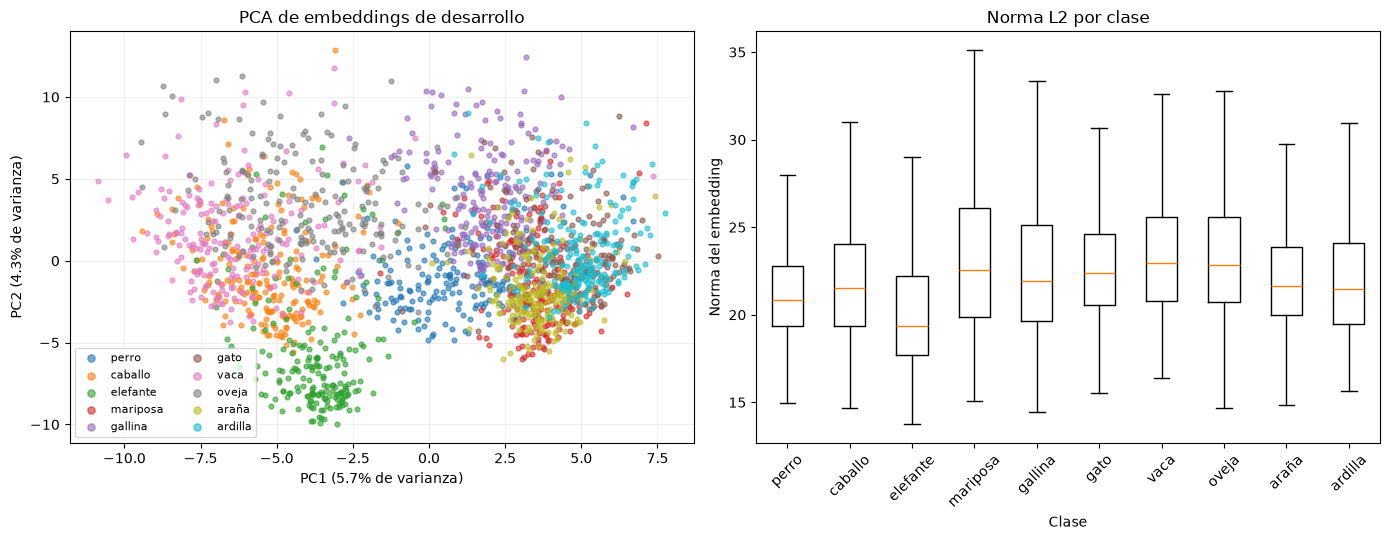

Varianza explicada por PC1 + PC2: 9.99%


In [11]:
from sklearn.decomposition import PCA

rng_pca = np.random.default_rng(SEED)
sample_indices = np.concatenate([
    rng_pca.choice(np.flatnonzero(development['class_name'].to_numpy() == name),
                   size=min(200, int((development['class_name'] == name).sum())),
                   replace=False)
    for name in CLASS_NAMES
])
sample_vectors = np.asarray(embeddings_check[sample_indices], dtype=np.float32)
pca = PCA(n_components=2, svd_solver='randomized', random_state=SEED)
coordinates = pca.fit_transform(sample_vectors)
projection = development.iloc[sample_indices][['relative_path', 'class_name', 'class_es']].copy()
projection['pca_1'] = coordinates[:, 0]
projection['pca_2'] = coordinates[:, 1]
projection.to_csv(ARTIFACTS_DIR / 'proyeccion_pca_desarrollo.csv', index=False)

norms = np.linalg.norm(embeddings_check, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = plt.get_cmap('tab10').colors
for index, name in enumerate(CLASS_NAMES):
    points = projection[projection['class_name'] == name]
    axes[0].scatter(points['pca_1'], points['pca_2'], s=12, alpha=0.6,
                    color=colors[index], label=CLASS_NAMES_ES[name])
axes[0].set(title='PCA de embeddings de desarrollo',
            xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} de varianza)',
            ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} de varianza)')
axes[0].legend(ncol=2, fontsize=8, markerscale=1.5)
axes[0].grid(alpha=0.2)
norm_groups = [norms[development['class_name'].to_numpy() == name] for name in CLASS_NAMES]
axes[1].boxplot(norm_groups, tick_labels=[CLASS_NAMES_ES[name] for name in CLASS_NAMES],
                showfliers=False)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set(title='Norma L2 por clase', xlabel='Clase', ylabel='Norma del embedding')
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_embeddings_desarrollo.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'Varianza explicada por PC1 + PC2: {pca.explained_variance_ratio_.sum():.2%}')

**Estado:** la etapa 3 termina con embeddings del conjunto de desarrollo, etiquetas alineadas por fila y gráficos exploratorios. La etapa 4 ajustará `StandardScaler` dentro de cada fold de validación cruzada y comparará regresión logística y SVM sin cargar el test.

### Selección de características

La rúbrica permite omitir una selección explícita de características en problemas de imágenes o transferencia de aprendizaje. Aquí MobileNetV2 congelada produce 1 280 características por imagen y los clasificadores reciben el vector completo. Se evita introducir un filtro adicional que podría descartar información visual útil y añadir otra decisión de hiperparámetros. El escalado se ajusta dentro de cada fold del pipeline para prevenir fuga de información.

PCA se utiliza únicamente para la dispersión exploratoria y para preparar la entrada de t-SNE. **Ninguna proyección PCA ni t-SNE interviene en la búsqueda, la comparación estadística o la predicción final.** Así se conserva la interpretación de la comparación entre clasificadores sobre la misma representación original.


## Etapa 4. Pipelines y optimización

El conjunto de desarrollo se divide en dos partes estratificadas por grupos. Una mitad se reserva para **comparación** en la etapa 5. De la otra mitad se toma una muestra estratificada por grupos de alrededor de 5 000 imágenes para **búsqueda**, por el costo de SVM en CPU. Las imágenes similares permanecen en una sola parte. El test de la etapa 2 sigue aislado.

Cada candidato es un `Pipeline(StandardScaler, clasificador)`, de modo que el escalador se ajusta únicamente con el entrenamiento de cada fold. La métrica principal es macro F1; accuracy y weighted F1 son complementarias. La validación usa cinco folds y dos repeticiones con estratificación por clase y grupos indivisibles.

In [12]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import f1_score

X_development = np.load(embeddings_path, mmap_mode='r')
labels_development = pd.read_csv(labels_path)
assert X_development.shape == (len(labels_development), EMBEDDING_DIM)
assert labels_development[['relative_path', 'class_name']].equals(
    development[['relative_path', 'class_name']])
y_development = labels_development['class_name'].to_numpy()
groups_development = labels_development['group_id'].to_numpy()

role_splitter = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED + 100)
role_candidates = []
overall_share = pd.Series(y_development).value_counts(normalize=True).reindex(CLASS_NAMES)
for search_idx, comparison_idx in role_splitter.split(
        X_development, y_development, groups_development):
    comparison_share = (pd.Series(y_development[comparison_idx]).value_counts(normalize=True)
                        .reindex(CLASS_NAMES, fill_value=0))
    deviation = (abs(len(comparison_idx) / len(y_development) - 0.5)
                 + (comparison_share - overall_share).abs().sum())
    role_candidates.append((deviation, search_idx, comparison_idx))
_, search_idx, comparison_idx = min(role_candidates, key=lambda item: item[0])
assert set(groups_development[search_idx]).isdisjoint(groups_development[comparison_idx])
assert set(y_development[search_idx]) == set(CLASS_NAMES)
assert set(y_development[comparison_idx]) == set(CLASS_NAMES)

search_pool_idx = search_idx
sub_splitter = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED + 101)
sub_candidates = []
pool_share = pd.Series(y_development[search_pool_idx]).value_counts(normalize=True).reindex(CLASS_NAMES)
for active_rel, unused_rel in sub_splitter.split(
        X_development[search_pool_idx], y_development[search_pool_idx],
        groups_development[search_pool_idx]):
    active_share = (pd.Series(y_development[search_pool_idx[active_rel]])
                    .value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0))
    deviation = (abs(len(active_rel) / len(search_pool_idx) - 0.5)
                 + (active_share - pool_share).abs().sum())
    sub_candidates.append((deviation, active_rel, unused_rel))
_, active_rel, unused_rel = min(sub_candidates, key=lambda item: item[0])
search_idx = search_pool_idx[active_rel]
unused_idx = search_pool_idx[unused_rel]
assert set(groups_development[search_idx]).isdisjoint(groups_development[unused_idx])

roles = labels_development.copy()
roles['role'] = 'comparison'
roles.loc[unused_idx, 'role'] = 'search_unused'
roles.loc[search_idx, 'role'] = 'search'
roles_path = ARTIFACTS_DIR / 'roles_desarrollo.csv'
roles.to_csv(roles_path, index=False)
X_search = np.asarray(X_development[search_idx], dtype=np.float32)
y_search = y_development[search_idx]
groups_search = groups_development[search_idx]

search_folds = []
for repetition in range(2):
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True,
                                    random_state=SEED + 200 + repetition)
    for train_idx, valid_idx in splitter.split(X_search, y_search, groups_search):
        assert set(groups_search[train_idx]).isdisjoint(groups_search[valid_idx])
        search_folds.append((train_idx, valid_idx))
assert len(search_folds) == 10
print(f'Búsqueda: {len(search_idx)} | Desarrollo no usado en búsqueda: {len(unused_idx)}')
print(f'Comparación reservada: {len(comparison_idx)}')
print(f'Folds de búsqueda: {len(search_folds)}; grupos sin cruces')
display(pd.crosstab(roles['class_name'], roles['role']))

Búsqueda: 5235 | Desarrollo no usado en búsqueda: 5235
Comparación reservada: 10471
Folds de búsqueda: 10; grupos sin cruces


role,comparison,search,search_unused
class_name,,,
cane,1945,972,973
cavallo,1050,525,524
elefante,578,290,289
farfalla,844,423,422
gallina,1239,619,620
gatto,667,333,334
mucca,746,373,373
pecora,728,364,364
ragno,1929,964,964


### Espacios de búsqueda

La regresión logística explora tres intensidades de regularización `C` y dos opciones de ponderación de clases, con regularización L2 y solver `lbfgs`. Para SVM se usa `LinearSVC` en la rama lineal y `SVC` en la rama RBF; se varían `C` y, en RBF, `gamma`. La rama lineal de `SVC` resultó demasiado costosa en CPU para diez folds, por lo que se sustituyó por `LinearSVC`. Se guardan media, desviación, tiempo y puntuaciones de cada fold.

In [13]:
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, solver='lbfgs', random_state=SEED)),
])
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LinearSVC(dual=True, max_iter=2000, tol=1e-2, random_state=SEED)),
])
logistic_grid = {
    'classifier__C': [0.1, 1.0, 10.0],
    'classifier__class_weight': [None, 'balanced'],
}
svm_grid = [
    {'classifier': [LinearSVC(dual=True, max_iter=2000, tol=1e-2, random_state=SEED)],
     'classifier__C': [0.1, 1.0],
     'classifier__class_weight': [None, 'balanced']},
    {'classifier': [SVC(kernel='rbf', cache_size=500, random_state=SEED)],
     'classifier__C': [1.0, 10.0],
     'classifier__gamma': ['scale', 0.01], 'classifier__class_weight': [None]},
]
scoring = {'macro_f1': 'f1_macro', 'accuracy': 'accuracy',
           'weighted_f1': 'f1_weighted'}
search_results = {}
for model_name, pipeline, grid in (
        ('logistic', logistic_pipeline, logistic_grid),
        ('svm', svm_pipeline, svm_grid)):
    print(f'Buscando {model_name}...')
    search = GridSearchCV(
        estimator=pipeline, param_grid=grid, scoring=scoring, refit='macro_f1',
        cv=search_folds, n_jobs=2, pre_dispatch=2, return_train_score=True,
        error_score='raise', verbose=0,
    )
    search.fit(X_search, y_search)
    search_results[model_name] = search
    print(f'Mejor macro F1 CV ({model_name}): {search.best_score_:.4f}')
    print(f'Parámetros: {search.best_params_}')

search_tables = []
for model_name, search in search_results.items():
    table = pd.DataFrame(search.cv_results_)
    table.insert(0, 'model', model_name)
    search_tables.append(table)
search_table = pd.concat(search_tables, ignore_index=True)
search_table.to_csv(ARTIFACTS_DIR / 'resultados_busqueda.csv', index=False)
best_config = {}
for name, search in search_results.items():
    params = search.best_params_.copy()
    if name == 'svm':
        params['classifier'] = type(params['classifier']).__name__
    best_config[name] = params
best_config['design'] = {
    'search_rows': int(len(search_idx)), 'comparison_rows': int(len(comparison_idx)),
    'folds': 5, 'repetitions': 2, 'seed': SEED, 'primary_metric': 'macro_f1',
    'linear_svc': {'dual': True, 'max_iter': 2000, 'tol': 0.01},
    'manifest_sha256': hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
}
(ARTIFACTS_DIR / 'configuracion_modelos.json').write_text(
    json.dumps(best_config, indent=2), encoding='utf-8')
display(search_table[['model', 'params', 'mean_test_macro_f1',
                      'std_test_macro_f1', 'mean_test_accuracy',
                      'mean_test_weighted_f1', 'mean_fit_time']]
        .sort_values(['model', 'mean_test_macro_f1'], ascending=[True, False]))

Buscando logistic...


Mejor macro F1 CV (logistic): 0.9518
Parámetros: {'classifier__C': 0.1, 'classifier__class_weight': None}
Buscando svm...


Mejor macro F1 CV (svm): 0.9541
Parámetros: {'classifier': SVC(cache_size=500, random_state=42), 'classifier__C': 10.0, 'classifier__class_weight': None, 'classifier__gamma': 'scale'}


,model,params,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_test_weighted_f1,mean_fit_time
0,logistic,"{'classifier__C': 0.1, 'classifier__class_weig...",0.951804,0.005093,0.955969,0.955950,0.393506
1,logistic,"{'classifier__C': 0.1, 'classifier__class_weig...",0.951337,0.004666,0.955968,0.955982,0.377933
2,logistic,"{'classifier__C': 1.0, 'classifier__class_weig...",0.950862,0.005601,0.955492,0.955458,0.149527
3,logistic,"{'classifier__C': 1.0, 'classifier__class_weig...",0.950698,0.005934,0.955683,0.955662,0.158382
5,logistic,"{'classifier__C': 10.0, 'classifier__class_wei...",0.949569,0.006314,0.954632,0.954586,0.146961
4,logistic,"{'classifier__C': 10.0, 'classifier__class_wei...",0.949515,0.006096,0.954155,0.954141,0.148513
12,svm,"{'classifier': SVC(cache_size=500, random_stat...",0.954063,0.004310,0.956541,0.956588,2.956258
10,svm,"{'classifier': SVC(cache_size=500, random_stat...",0.950751,0.004505,0.953580,0.953614,1.659028
8,svm,"{'classifier': LinearSVC(dual=True, max_iter=2...",0.942822,0.006535,0.948233,0.948264,4.800714
7,svm,"{'classifier': LinearSVC(dual=True, max_iter=2...",0.942818,0.006386,0.948233,0.948255,4.077382


### Sensibilidad a hiperparámetros

Las gráficas muestran cómo cambia macro F1 con `C`. La segunda distingue kernel y `gamma` para SVM. Las barras de error representan la desviación estándar entre los diez folds; son descriptivas y no intervalos de confianza independientes, porque los folds repetidos comparten imágenes.

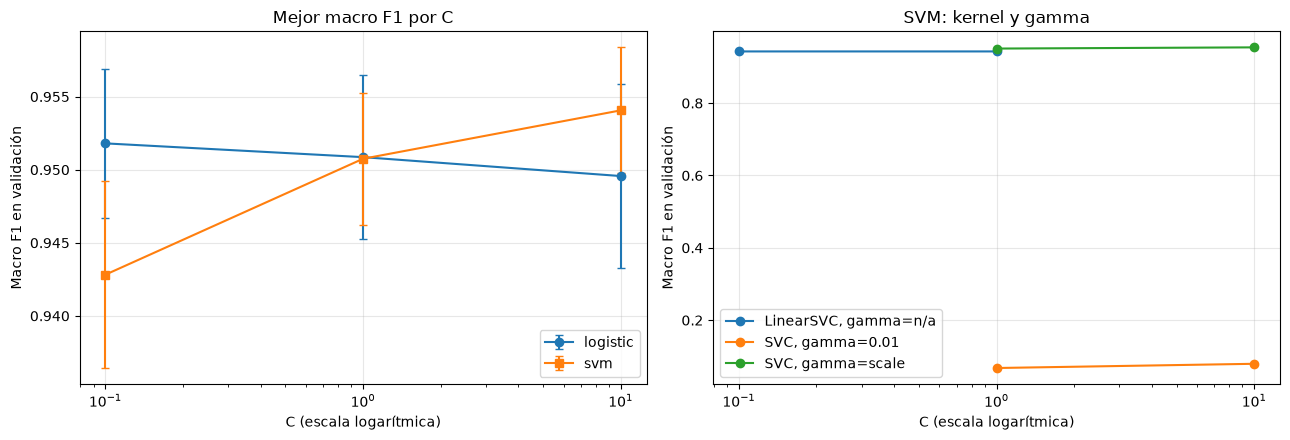

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for model_name, marker in (('logistic', 'o'), ('svm', 's')):
    subset = search_table[search_table['model'] == model_name].copy()
    subset['C'] = subset['param_classifier__C'].astype(float)
    summary = (subset.sort_values('mean_test_macro_f1', ascending=False)
               .drop_duplicates('C').sort_values('C'))
    axes[0].errorbar(summary['C'], summary['mean_test_macro_f1'],
                     yerr=summary['std_test_macro_f1'],
                     marker=marker, capsize=3, label=model_name)
axes[0].set_xscale('log')
axes[0].set(title='Mejor macro F1 por C', xlabel='C (escala logarítmica)',
            ylabel='Macro F1 en validación')
axes[0].legend()
axes[0].grid(alpha=0.3)

svm_rows = search_table[search_table['model'] == 'svm'].copy()
for label, group in svm_rows.groupby(svm_rows['params'].map(
        lambda p: f"{type(p['classifier']).__name__}, gamma={p.get('classifier__gamma', 'n/a')}")):
    group = (group.sort_values('mean_test_macro_f1', ascending=False)
             .drop_duplicates('param_classifier__C')
             .sort_values('param_classifier__C'))
    axes[1].plot(group['param_classifier__C'].astype(float),
                 group['mean_test_macro_f1'], marker='o', label=label)
axes[1].set_xscale('log')
axes[1].set(title='SVM: kernel y gamma', xlabel='C (escala logarítmica)',
            ylabel='Macro F1 en validación')
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_hiperparametros.png', dpi=180, bbox_inches='tight')
plt.show()

### Dispersión de rendimiento y costo

Cada punto representa una configuración de búsqueda. El eje horizontal muestra su tiempo medio de ajuste por fold y el vertical su macro F1 medio. El panel izquierdo incluye todos los candidatos y el derecho amplía los competitivos; el color distingue regresión logística y SVM. Esta gráfica permite ver si una mejora pequeña exige mucho más cómputo.

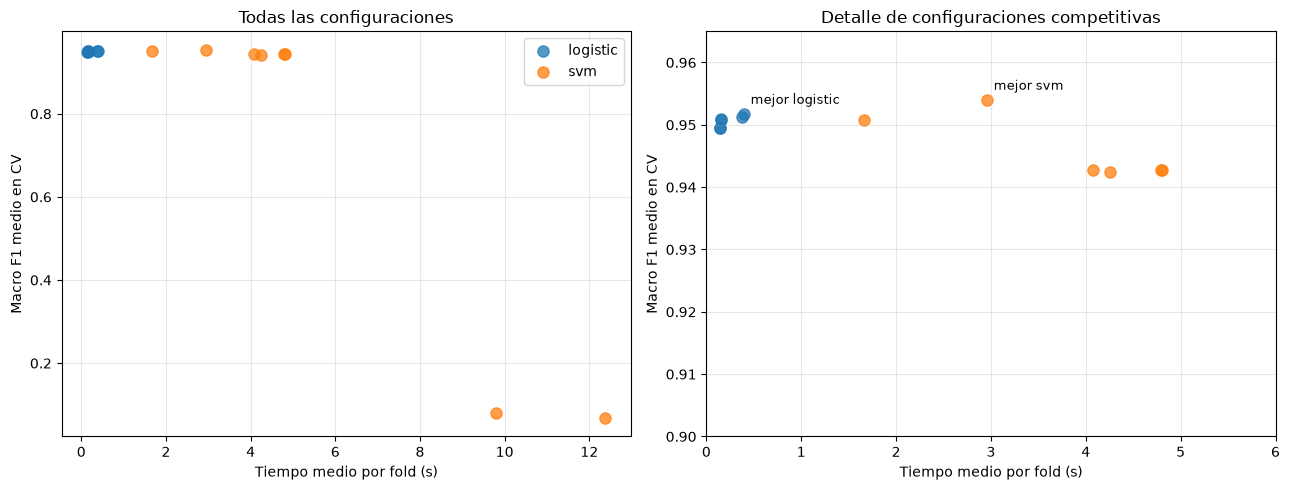

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis in axes:
    for model_name, color in (('logistic', 'tab:blue'), ('svm', 'tab:orange')):
        subset = search_table[search_table['model'] == model_name]
        axis.scatter(subset['mean_fit_time'], subset['mean_test_macro_f1'],
                     s=65, alpha=0.75, color=color, label=model_name)
    axis.set(xlabel='Tiempo medio por fold (s)', ylabel='Macro F1 medio en CV')
    axis.grid(alpha=0.3)
axes[0].set_title('Todas las configuraciones')
axes[0].legend()
axes[1].set_title('Detalle de configuraciones competitivas')
axes[1].set_ylim(0.90, 0.965)
axes[1].set_xlim(0, 6)
for model_name in ('logistic', 'svm'):
    subset = search_table[search_table['model'] == model_name]
    best_row = subset.loc[subset['mean_test_macro_f1'].idxmax()]
    axes[1].annotate(f'mejor {model_name}',
                     (best_row['mean_fit_time'], best_row['mean_test_macro_f1']),
                     xytext=(5, 7), textcoords='offset points', fontsize=9)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_rendimiento_tiempo.png', dpi=180, bbox_inches='tight')
plt.show()

### Curvas de aprendizaje

Para cada mejor configuración se usan tres folds de la búsqueda y tamaños crecientes del entrenamiento. Se presentan puntuaciones de entrenamiento y validación para estudiar si más datos podrían ayudar. La comparación estadística formal se hará en la etapa 5 con la mitad reservada.

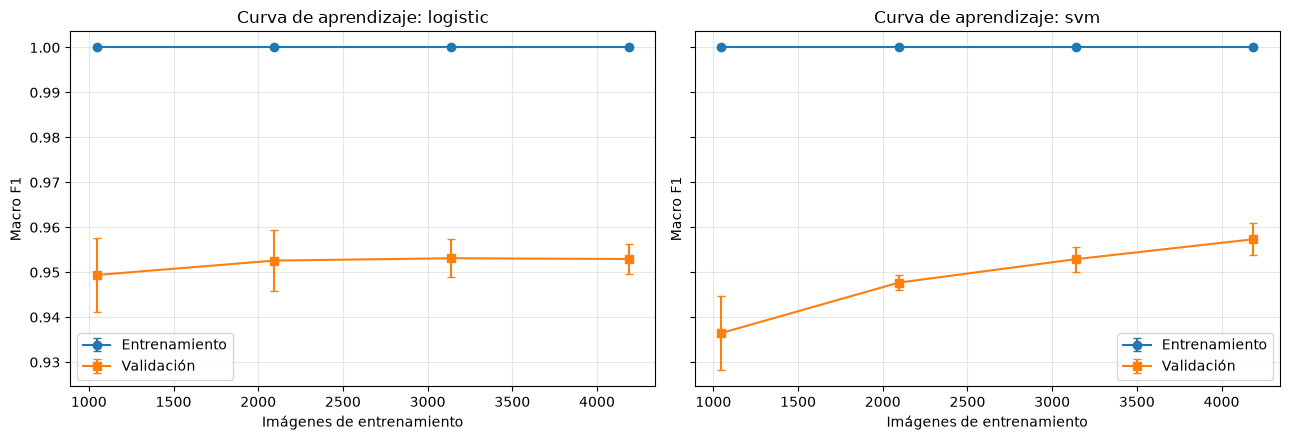

,model,train_size,train_mean,train_std,valid_mean,valid_std
0,logistic,1047,1.0,0.0,0.9494,0.0083
1,logistic,2094,1.0,0.0,0.9526,0.0069
2,logistic,3141,1.0,0.0,0.9531,0.0042
3,logistic,4188,1.0,0.0,0.9529,0.0033
4,svm,1047,1.0,0.0,0.9365,0.0083
5,svm,2094,1.0,0.0,0.9477,0.0018
6,svm,3141,1.0,0.0,0.9529,0.0028
7,svm,4188,1.0,0.0,0.9573,0.0036


In [16]:
from sklearn.model_selection import learning_curve

curve_folds = search_folds[:3]
curve_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for axis, (model_name, search) in zip(axes, search_results.items()):
    sizes, train_scores, valid_scores = learning_curve(
        search.best_estimator_, X_search, y_search, cv=curve_folds,
        train_sizes=[0.25, 0.5, 0.75, 1.0], scoring='f1_macro',
        n_jobs=2, pre_dispatch=2, shuffle=True, random_state=SEED,
        error_score='raise',
    )
    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    valid_mean, valid_std = valid_scores.mean(axis=1), valid_scores.std(axis=1)
    axis.errorbar(sizes, train_mean, yerr=train_std, marker='o', capsize=3,
                  label='Entrenamiento')
    axis.errorbar(sizes, valid_mean, yerr=valid_std, marker='s', capsize=3,
                  label='Validación')
    axis.set(title=f'Curva de aprendizaje: {model_name}',
             xlabel='Imágenes de entrenamiento', ylabel='Macro F1')
    axis.grid(alpha=0.3)
    axis.legend()
    for size, tr_mean, tr_std, va_mean, va_std in zip(
            sizes, train_mean, train_std, valid_mean, valid_std):
        curve_rows.append({'model': model_name, 'train_size': int(size),
                           'train_mean': tr_mean, 'train_std': tr_std,
                           'valid_mean': va_mean, 'valid_std': va_std})
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_curvas_aprendizaje.png', dpi=180, bbox_inches='tight')
plt.show()
curve_table = pd.DataFrame(curve_rows)
curve_table.to_csv(ARTIFACTS_DIR / 'curvas_aprendizaje.csv', index=False)
display(curve_table.round(4))

**Estado:** la etapa 4 termina con hiperparámetros fijados y resultados completos de búsqueda. La mitad de comparación permanece sin utilizar; la etapa 5 aplicará ambas configuraciones a los mismos folds de esa mitad y evaluará la diferencia pareada.

## Etapa 5. Comparación estadística pareada

**H0:** la diferencia media esperada de macro F1 entre SVM y regresión logística es cero. **H1:** la diferencia es distinta de cero. Se fija `alpha = 0,05` y se define la diferencia como `macro F1(SVM) - macro F1(logística)`, por lo que un valor positivo favorece a SVM.

Se aplican los hiperparámetros fijados en la etapa 4 a diez folds nuevos de la parte de comparación, con los mismos índices para ambos modelos y grupos de imágenes indivisibles. El test final sigue reservado. La inferencia principal usa el t-test corregido de Nadeau y Bengio, que aumenta la varianza estimada para reconocer que los folds repetidos comparten datos. La prueba de Shapiro y las pruebas pareadas ordinarias se reportan solo como diagnósticos y análisis de sensibilidad.

In [17]:
from time import perf_counter
from scipy import stats
from sklearn.metrics import accuracy_score

ALPHA = 0.05
PRACTICAL_MARGIN = 0.005  # 0,5 puntos porcentuales de macro F1
config_path = ARTIFACTS_DIR / 'configuracion_modelos.json'
roles_path = ARTIFACTS_DIR / 'roles_desarrollo.csv'
best_config = json.loads(config_path.read_text(encoding='utf-8'))
roles = pd.read_csv(roles_path)
assert best_config['design']['manifest_sha256'] == hashlib.sha256(
    manifest_path.read_bytes()).hexdigest()
assert roles[['relative_path', 'class_name']].equals(
    labels_development[['relative_path', 'class_name']])
assert (roles.groupby('group_id')['role'].nunique() == 1).all()
comparison_idx = np.flatnonzero(roles['role'].to_numpy() == 'comparison')
X_comparison = np.asarray(X_development[comparison_idx], dtype=np.float32)
y_comparison = y_development[comparison_idx]
groups_comparison = groups_development[comparison_idx]
comparison_folds = []
for repetition in range(2):
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True,
                                    random_state=SEED + 300 + repetition)
    for fold, (train_idx, valid_idx) in enumerate(
            splitter.split(X_comparison, y_comparison, groups_comparison), start=1):
        assert set(groups_comparison[train_idx]).isdisjoint(groups_comparison[valid_idx])
        comparison_folds.append((repetition + 1, fold, train_idx, valid_idx))
assert len(comparison_folds) == 10

logistic_params = best_config['logistic']
logistic_fixed = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        C=logistic_params['classifier__C'],
        class_weight=logistic_params['classifier__class_weight'],
        max_iter=1000, solver='lbfgs', random_state=SEED)),
])
svm_params = best_config['svm']
if svm_params['classifier'] == 'SVC':
    svm_classifier = SVC(
        kernel='rbf', C=svm_params['classifier__C'],
        gamma=svm_params['classifier__gamma'],
        class_weight=svm_params['classifier__class_weight'],
        cache_size=500, random_state=SEED)
elif svm_params['classifier'] == 'LinearSVC':
    svm_classifier = LinearSVC(
        C=svm_params['classifier__C'],
        class_weight=svm_params['classifier__class_weight'],
        random_state=SEED, **best_config['design']['linear_svc'])
else:
    raise ValueError(f'Clasificador SVM no reconocido: {svm_params["classifier"]}')
svm_fixed = Pipeline([('scaler', StandardScaler()), ('classifier', svm_classifier)])
print(f'Comparación: {len(comparison_idx)} imágenes, {len(comparison_folds)} folds pareados')
print('Configuraciones fijas:', logistic_params, svm_params)

Comparación: 10471 imágenes, 10 folds pareados
Configuraciones fijas: {'classifier__C': 0.1, 'classifier__class_weight': None} {'classifier': 'SVC', 'classifier__C': 10.0, 'classifier__class_weight': None, 'classifier__gamma': 'scale'}


### Puntuaciones en folds idénticos

Cada modelo se vuelve a ajustar dentro de cada fold. Se calculan macro F1, accuracy y weighted F1 en la validación; la tabla conserva también el tamaño de entrenamiento y validación y los tiempos de ajuste. Se escribe el CSV después de cada fold para dejar avance verificable.

In [18]:
from sklearn.base import clone

comparison_rows = []
scores_path = ARTIFACTS_DIR / 'scores_comparacion.csv'
for repetition, fold, train_idx, valid_idx in comparison_folds:
    row = {'repetition': repetition, 'fold': fold,
           'n_train': len(train_idx), 'n_valid': len(valid_idx)}
    for model_name, pipeline in (('logistic', logistic_fixed), ('svm', svm_fixed)):
        model = clone(pipeline)
        start = perf_counter()
        model.fit(X_comparison[train_idx], y_comparison[train_idx])
        row[f'fit_seconds_{model_name}'] = perf_counter() - start
        predictions = model.predict(X_comparison[valid_idx])
        row[f'macro_f1_{model_name}'] = f1_score(
            y_comparison[valid_idx], predictions, average='macro')
        row[f'weighted_f1_{model_name}'] = f1_score(
            y_comparison[valid_idx], predictions, average='weighted')
        row[f'accuracy_{model_name}'] = accuracy_score(
            y_comparison[valid_idx], predictions)
    row['delta_macro_f1'] = row['macro_f1_svm'] - row['macro_f1_logistic']
    comparison_rows.append(row)
    pd.DataFrame(comparison_rows).to_csv(scores_path, index=False)
    print(f'Repetición {repetition}, fold {fold}: '          f'logística={row["macro_f1_logistic"]:.4f}, '          f'SVM={row["macro_f1_svm"]:.4f}, '          f'diferencia={row["delta_macro_f1"]:+.4f}')
scores_comparison = pd.DataFrame(comparison_rows)
assert len(scores_comparison) == 10
display(scores_comparison.round(4))

Repetición 1, fold 1: logística=0.9501, SVM=0.9553, diferencia=+0.0053


Repetición 1, fold 2: logística=0.9590, SVM=0.9626, diferencia=+0.0036


Repetición 1, fold 3: logística=0.9558, SVM=0.9580, diferencia=+0.0021


Repetición 1, fold 4: logística=0.9570, SVM=0.9672, diferencia=+0.0102


Repetición 1, fold 5: logística=0.9597, SVM=0.9672, diferencia=+0.0075


Repetición 2, fold 1: logística=0.9546, SVM=0.9658, diferencia=+0.0111


Repetición 2, fold 2: logística=0.9522, SVM=0.9603, diferencia=+0.0081


Repetición 2, fold 3: logística=0.9502, SVM=0.9546, diferencia=+0.0045


Repetición 2, fold 4: logística=0.9604, SVM=0.9624, diferencia=+0.0020


Repetición 2, fold 5: logística=0.9569, SVM=0.9668, diferencia=+0.0099


,repetition,fold,n_train,n_valid,fit_seconds_logistic,macro_f1_logistic,weighted_f1_logistic,accuracy_logistic,fit_seconds_svm,macro_f1_svm,weighted_f1_svm,accuracy_svm,delta_macro_f1
0,1,1,8376,2095,3.7545,0.9501,0.9562,0.9561,6.3492,0.9553,0.9589,0.9589,0.0053
1,1,2,8377,2094,2.0005,0.9590,0.9628,0.9628,6.2121,0.9626,0.9661,0.9661,0.0036
2,1,3,8376,2095,1.5338,0.9558,0.9603,0.9604,6.1293,0.9580,0.9617,0.9618,0.0021
3,1,4,8377,2094,0.9806,0.9570,0.9618,0.9618,6.1617,0.9672,0.9694,0.9694,0.0102
4,1,5,8378,2093,1.0051,0.9597,0.9623,0.9623,6.9222,0.9672,0.9690,0.9689,0.0075
5,2,1,8376,2095,1.2564,0.9546,0.9584,0.9585,7.2177,0.9658,0.9679,0.9680,0.0111
6,2,2,8376,2095,0.9899,0.9522,0.9575,0.9575,7.3060,0.9603,0.9632,0.9632,0.0081
7,2,3,8377,2094,2.2112,0.9502,0.9547,0.9546,9.3588,0.9546,0.9590,0.9589,0.0045
8,2,4,8377,2094,1.0332,0.9604,0.9655,0.9656,8.1346,0.9624,0.9670,0.9670,0.0020
9,2,5,8378,2093,0.9953,0.9569,0.9609,0.9608,7.9861,0.9668,0.9693,0.9694,0.0099


### Inferencia e interpretación

El t-test corregido utiliza `SE = sqrt((1/10 + n_valid/n_train) × varianza de las diferencias)`, con la razón de tamaños promediada entre folds y 9 grados de libertad. Se reportan un intervalo aproximado del 95 %, valor p bilateral, dirección y tamaño de efecto descriptivo `d_z`. El umbral práctico de 0,005 macro F1 (medio punto porcentual) se fija para discutir magnitud; no cambia la prueba de significancia. Shapiro, t pareado común y Wilcoxon se muestran como sensibilidad, porque los folds no son independientes. No rechazar H0 no demuestra equivalencia.

In [19]:
differences = scores_comparison['delta_macro_f1'].to_numpy()
n_pairs = len(differences)
difference_mean = float(differences.mean())
difference_sd = float(differences.std(ddof=1))
test_train_ratio = float((scores_comparison['n_valid'] / scores_comparison['n_train']).mean())
corrected_se = difference_sd * np.sqrt(1 / n_pairs + test_train_ratio)
degrees_freedom = n_pairs - 1
if corrected_se == 0:
    corrected_t = 0.0 if difference_mean == 0 else np.sign(difference_mean) * np.inf
    corrected_p = 1.0 if difference_mean == 0 else 0.0
else:
    corrected_t = difference_mean / corrected_se
    corrected_p = float(2 * stats.t.sf(abs(corrected_t), degrees_freedom))
critical_t = stats.t.ppf(1 - ALPHA / 2, degrees_freedom)
ci_low = float(difference_mean - critical_t * corrected_se)
ci_high = float(difference_mean + critical_t * corrected_se)
shapiro_p = float(stats.shapiro(differences).pvalue)
ordinary_p = float(stats.ttest_rel(
    scores_comparison['macro_f1_svm'],
    scores_comparison['macro_f1_logistic']).pvalue)
wilcoxon_p = float(stats.wilcoxon(differences).pvalue) if np.any(differences) else 1.0
effect_dz = float(difference_mean / difference_sd) if difference_sd else 0.0
result_inference = {
    'alpha': ALPHA, 'practical_margin_macro_f1': PRACTICAL_MARGIN,
    'pairs': n_pairs, 'mean_macro_f1_logistic': float(scores_comparison['macro_f1_logistic'].mean()),
    'mean_macro_f1_svm': float(scores_comparison['macro_f1_svm'].mean()),
    'mean_difference_svm_minus_logistic': difference_mean,
    'difference_sd': difference_sd, 'corrected_standard_error': float(corrected_se),
    'corrected_t': float(corrected_t), 'corrected_p_two_sided': corrected_p,
    'corrected_ci95': [ci_low, ci_high], 'cohen_dz_descriptive': effect_dz,
    'shapiro_p': shapiro_p, 'ordinary_paired_t_p': ordinary_p,
    'wilcoxon_p': wilcoxon_p, 'mean_valid_train_ratio': test_train_ratio,
    'reject_h0_corrected': bool(corrected_p < ALPHA),
}
(ARTIFACTS_DIR / 'resumen_inferencia.json').write_text(
    json.dumps(result_inference, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([result_inference]).T.rename(columns={0: 'valor'}))
if corrected_p < ALPHA:
    print('Decisión: se rechaza H0 con la corrección por folds repetidos.')
else:
    print('Decisión: no se rechaza H0 con la corrección por folds repetidos.')
print(f'Diferencia media SVM - logística: {difference_mean:+.4f}; '      f'IC 95 % corregido [{ci_low:+.4f}, {ci_high:+.4f}]')

,valor
alpha,0.05
practical_margin_macro_f1,0.005
pairs,10
mean_macro_f1_logistic,0.955603
mean_macro_f1_svm,0.962023
mean_difference_svm_minus_logistic,0.006419
difference_sd,0.003386
corrected_standard_error,0.002003
corrected_t,3.204941
corrected_p_two_sided,0.010746


Decisión: se rechaza H0 con la corrección por folds repetidos.
Diferencia media SVM - logística: +0.0064; IC 95 % corregido [+0.0019, +0.0110]


### Gráficos de la comparación

La primera figura une las puntuaciones de ambos modelos en cada fold y las coloca en una dispersión con diagonal de igualdad. La segunda muestra las diez diferencias y un intervalo corregido de la diferencia media, junto con un gráfico Q-Q para examinar la forma de la distribución. Las líneas en ±0,005 indican el umbral de relevancia práctica elegido para la discusión.

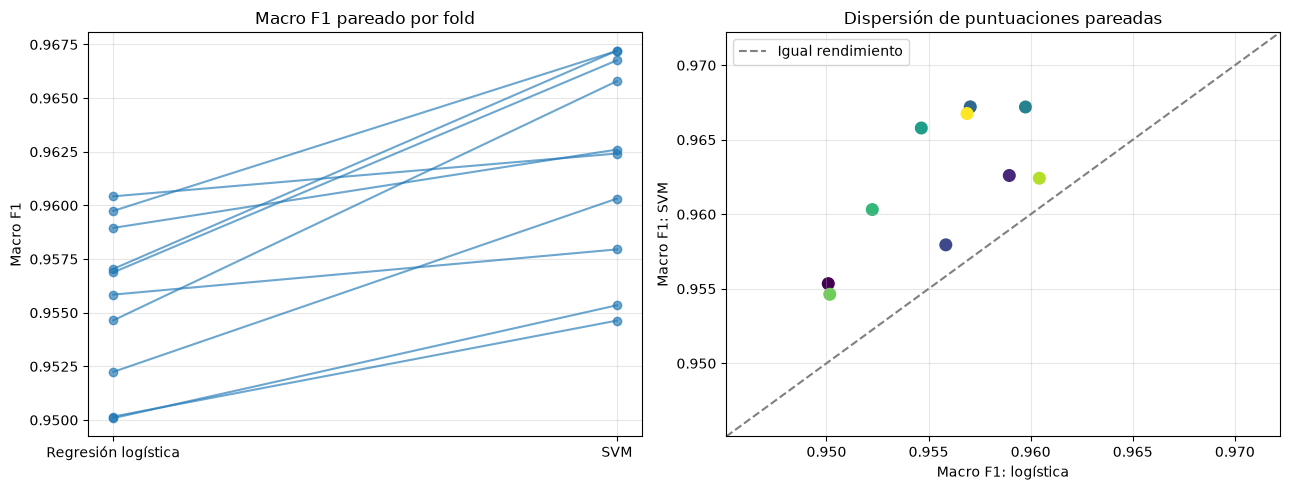

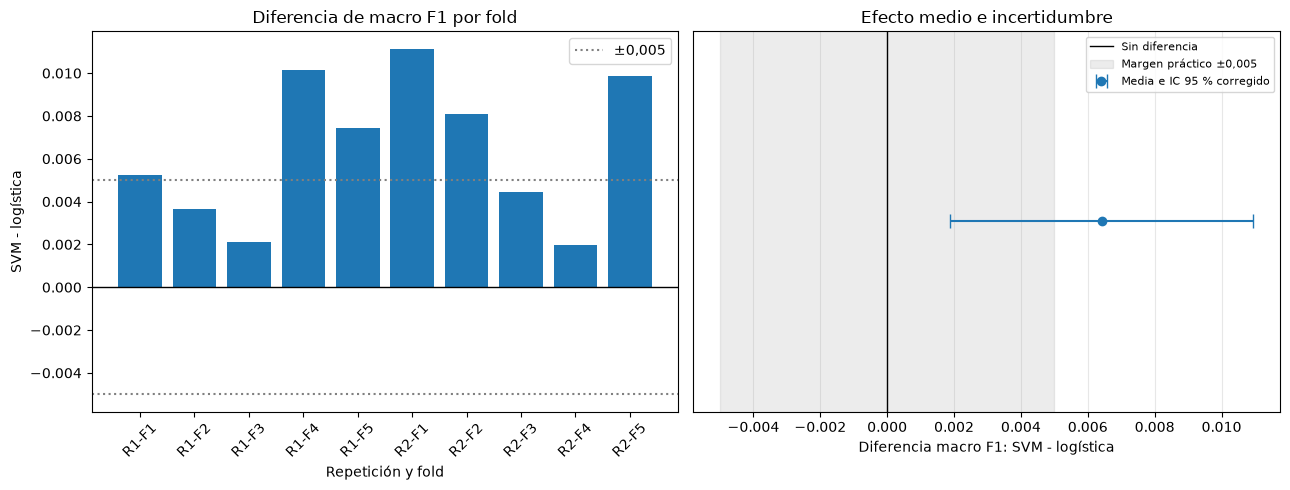

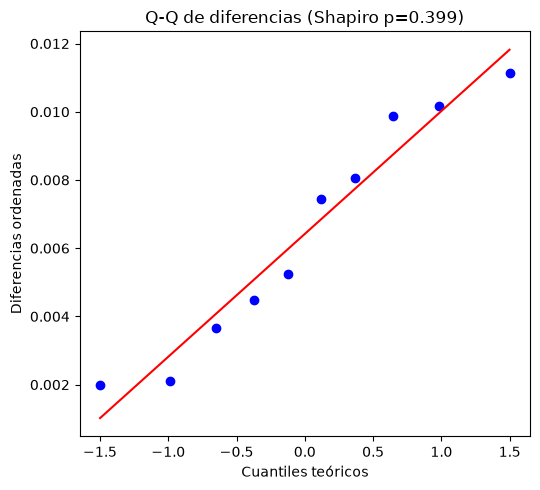

In [20]:
fold_labels = [f'R{r}-F{f}' for r, f in zip(
    scores_comparison['repetition'], scores_comparison['fold'])]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for index, row in scores_comparison.iterrows():
    axes[0].plot([0, 1], [row['macro_f1_logistic'], row['macro_f1_svm']],
                 marker='o', alpha=0.65, color='tab:blue' if row['delta_macro_f1'] >= 0
                 else 'tab:orange')
axes[0].set_xticks([0, 1], ['Regresión logística', 'SVM'])
axes[0].set(title='Macro F1 pareado por fold', ylabel='Macro F1')
axes[0].grid(alpha=0.3)
axes[1].scatter(scores_comparison['macro_f1_logistic'],
                scores_comparison['macro_f1_svm'], c=range(n_pairs), cmap='viridis', s=70)
limits = [min(scores_comparison[['macro_f1_logistic', 'macro_f1_svm']].min()) - 0.005,
          max(scores_comparison[['macro_f1_logistic', 'macro_f1_svm']].max()) + 0.005]
axes[1].plot(limits, limits, '--', color='gray', label='Igual rendimiento')
axes[1].set(xlim=limits, ylim=limits, title='Dispersión de puntuaciones pareadas',
            xlabel='Macro F1: logística', ylabel='Macro F1: SVM')
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_comparacion_pareada.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bar_colors = ['tab:blue' if value >= 0 else 'tab:orange' for value in differences]
axes[0].bar(fold_labels, differences, color=bar_colors)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].axhline(PRACTICAL_MARGIN, color='gray', linestyle=':', label='±0,005')
axes[0].axhline(-PRACTICAL_MARGIN, color='gray', linestyle=':')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set(title='Diferencia de macro F1 por fold',
            xlabel='Repetición y fold', ylabel='SVM - logística')
axes[0].legend()
axes[1].errorbar(difference_mean, 0, xerr=[[difference_mean - ci_low],
                [ci_high - difference_mean]], fmt='o', capsize=5, color='tab:blue',
                label='Media e IC 95 % corregido')
axes[1].axvline(0, color='black', linewidth=1, label='Sin diferencia')
axes[1].axvspan(-PRACTICAL_MARGIN, PRACTICAL_MARGIN, color='gray', alpha=0.15,
                label='Margen práctico ±0,005')
axes[1].set(yticks=[], title='Efecto medio e incertidumbre',
            xlabel='Diferencia macro F1: SVM - logística')
axes[1].legend(fontsize=8)
axes[1].grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_diferencias_comparacion.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axis = plt.subplots(figsize=(5.5, 5))
stats.probplot(differences, dist='norm', plot=axis)
axis.set(title=f'Q-Q de diferencias (Shapiro p={shapiro_p:.3f})',
         xlabel='Cuantiles teóricos', ylabel='Diferencias ordenadas')
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_qq_diferencias.png', dpi=180, bbox_inches='tight')
plt.show()

**Estado:** la etapa 5 termina con las puntuaciones pareadas, una prueba corregida por dependencia, análisis de sensibilidad y gráficos. La etapa 6 podrá seleccionar el modelo principal con esta evidencia, reentrenarlo en todo desarrollo y usar el test reservado una sola vez.

## Etapa 6. Test final y análisis visual

La comparación independiente de la etapa 5 seleccionó SVM RBF como modelo principal. Se ajusta una sola vez con **todo desarrollo** y se evalúa en las 5 236 imágenes de test reservadas desde la etapa 2. El test no se usa para elegir hiperparámetros ni para alterar el modelo. La predicción se guarda con una huella de la configuración para evitar repetirla en ejecuciones idénticas.

Después de la evaluación se presentan métricas por clase, matriz de confusión y ejemplos de aciertos y errores. t-SNE usa una muestra estratificada de **desarrollo** y es únicamente exploratorio.

In [21]:
test_manifest = manifest.loc[manifest['split'] == 'test'].reset_index(drop=True)
assert len(test_manifest) == 5236
assert set(test_manifest['group_id']).isdisjoint(development['group_id'])
test_paths = test_manifest['relative_path'].tolist()
missing_test = [path for path in test_paths if not (PROJECT_ROOT / path).is_file()]
if missing_test:
    raise FileNotFoundError(f'Faltan {len(missing_test)} imágenes de test')
test_embeddings_path = ARTIFACTS_DIR / 'embeddings_test.npy'
test_metadata_path = ARTIFACTS_DIR / 'embeddings_test_meta.json'
test_progress_path = ARTIFACTS_DIR / 'embeddings_test_progreso.json'
test_metadata = {
    'manifest_sha256': hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    'tensorflow_version': tf.__version__, 'model': 'MobileNetV2',
    'weights': 'imagenet', 'pooling': 'avg', 'image_size': list(IMAGE_SIZE),
    'embedding_dim': EMBEDDING_DIM, 'rows': len(test_manifest), 'dtype': 'float32',
}
test_cache_valid = False
if test_embeddings_path.is_file() and test_metadata_path.is_file():
    saved = json.loads(test_metadata_path.read_text(encoding='utf-8'))
    if saved == test_metadata:
        test_cache_valid = np.load(test_embeddings_path, mmap_mode='r').shape == (
            len(test_manifest), EMBEDDING_DIM)
if not test_cache_valid:
    next_index = 0
    if test_progress_path.is_file() and test_embeddings_path.is_file():
        progress = json.loads(test_progress_path.read_text(encoding='utf-8'))
        if progress.get('metadata') == test_metadata:
            next_index = int(progress['next_index'])
    if next_index:
        test_vectors = open_memmap(test_embeddings_path, mode='r+')
        assert test_vectors.shape == (len(test_manifest), EMBEDDING_DIM)
    else:
        test_vectors = open_memmap(test_embeddings_path, mode='w+',
                                   dtype=np.float32,
                                   shape=(len(test_manifest), EMBEDDING_DIM))
    for start in range(next_index, len(test_manifest), BATCH_SIZE):
        end = min(start + BATCH_SIZE, len(test_manifest))
        batch = load_preprocessed_batch(test_paths[start:end])
        vectors = extractor(batch, training=False).numpy()
        if vectors.shape != (end - start, EMBEDDING_DIM) or not np.isfinite(vectors).all():
            raise ValueError(f'Embeddings de test inválidos en {start}:{end}')
        test_vectors[start:end] = vectors.astype(np.float32, copy=False)
        test_vectors.flush()
        test_progress_path.write_text(json.dumps(
            {'metadata': test_metadata, 'next_index': end}), encoding='utf-8')
        if end % (BATCH_SIZE * 50) == 0 or end == len(test_manifest):
            print(f'Test procesado: {end}/{len(test_manifest)}')
    del test_vectors
    test_metadata_path.write_text(json.dumps(test_metadata, indent=2), encoding='utf-8')
    test_progress_path.unlink(missing_ok=True)
else:
    print('Embeddings de test recuperados de la caché')
X_test = np.load(test_embeddings_path, mmap_mode='r')
assert X_test.shape == (len(test_manifest), EMBEDDING_DIM)
assert np.isfinite(X_test).all()
y_test = test_manifest['class_name'].to_numpy()
print(f'Matriz de test: {X_test.shape}')

Test procesado: 1600/5236


Test procesado: 3200/5236


Test procesado: 4800/5236


Test procesado: 5236/5236
Matriz de test: (5236, 1280)


### Ajuste final y predicción única

El pipeline completo, incluido `StandardScaler`, se ajusta sobre las 20 941 imágenes de desarrollo. Se guardan modelo y predicciones. Las puntuaciones de decisión de SVM permiten ordenar ejemplos para inspección, pero **no son probabilidades calibradas**. Una ejecución posterior con la misma huella reutiliza las predicciones guardadas.

In [22]:
import joblib

inference_summary = json.loads((ARTIFACTS_DIR / 'resumen_inferencia.json').read_text(encoding='utf-8'))
if not (inference_summary['reject_h0_corrected'] and
        inference_summary['mean_difference_svm_minus_logistic'] > 0):
    raise ValueError('Revisar la selección del modelo antes de usar el test')
selection = {
    'model': 'svm_rbf',
    'config_sha256': hashlib.sha256(config_path.read_bytes()).hexdigest(),
    'inference_sha256': hashlib.sha256(
        (ARTIFACTS_DIR / 'resumen_inferencia.json').read_bytes()).hexdigest(),
    'manifest_sha256': hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    'test_embeddings': test_metadata,
}
predictions_path = ARTIFACTS_DIR / 'predicciones_test.csv'
prediction_meta_path = ARTIFACTS_DIR / 'predicciones_test_meta.json'
final_model_path = ARTIFACTS_DIR / 'modelo_final_svm.joblib'
predictions_cached = False
if predictions_path.is_file() and prediction_meta_path.is_file():
    saved_selection = json.loads(prediction_meta_path.read_text(encoding='utf-8'))
    if saved_selection == selection:
        saved_predictions = pd.read_csv(predictions_path)
        predictions_cached = (len(saved_predictions) == len(test_manifest) and
            saved_predictions['relative_path'].tolist() == test_paths and
            saved_predictions['true_class'].tolist() == y_test.tolist())
if predictions_cached:
    test_predictions = saved_predictions
    print('Predicciones finales recuperadas de la caché; no se repite el ajuste ni el test')
else:
    final_model = clone(svm_fixed)
    final_model.fit(X_development, y_development)
    predicted = final_model.predict(X_test)
    decision_scores = final_model.decision_function(X_test)
    sorted_scores = np.sort(decision_scores, axis=1)
    score_gap = sorted_scores[:, -1] - sorted_scores[:, -2]
    test_predictions = test_manifest[['relative_path', 'class_name', 'class_es']].rename(
        columns={'class_name': 'true_class', 'class_es': 'true_class_es'}).copy()
    test_predictions['predicted_class'] = predicted
    test_predictions['predicted_class_es'] = [CLASS_NAMES_ES[name] for name in predicted]
    test_predictions['score_gap_top2'] = score_gap
    test_predictions['correct'] = predicted == y_test
    test_predictions.to_csv(predictions_path, index=False)
    joblib.dump(final_model, final_model_path, compress=3)
    prediction_meta_path.write_text(json.dumps(
        selection, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'Modelo final: {final_model_path}')
print(f'Predicciones evaluables: {len(test_predictions)}')

Modelo final: C:\Users\rober\Documents\USFQ_IA\4_Aprendizaje Supervisado\Tareas\ProyectoFinal\artifacts\modelo_final_svm.joblib
Predicciones evaluables: 5236


### Métricas y matriz de confusión

Se reportan accuracy, macro F1, weighted F1, precisión y recall por clase. La matriz se normaliza por clase real para comparar errores entre clases de distinto tamaño; cada celda también muestra el conteo absoluto. Ninguna cifra de test se utilizó durante la selección.

,precision,recall,f1-score,support
perro,0.9525,0.9887,0.9702,973.0
caballo,0.9692,0.9599,0.9645,524.0
elefante,0.9928,0.9585,0.9754,289.0
mariposa,0.9714,0.9668,0.9691,422.0
gallina,0.9792,0.9887,0.9839,620.0
gato,0.9877,0.9641,0.9758,334.0
vaca,0.9471,0.9115,0.9290,373.0
oveja,0.9530,0.9478,0.9504,364.0
araña,0.9875,0.9844,0.9860,964.0
ardilla,0.9786,0.9812,0.9799,373.0


Accuracy=0.9712; macro F1=0.9684; weighted F1=0.9711


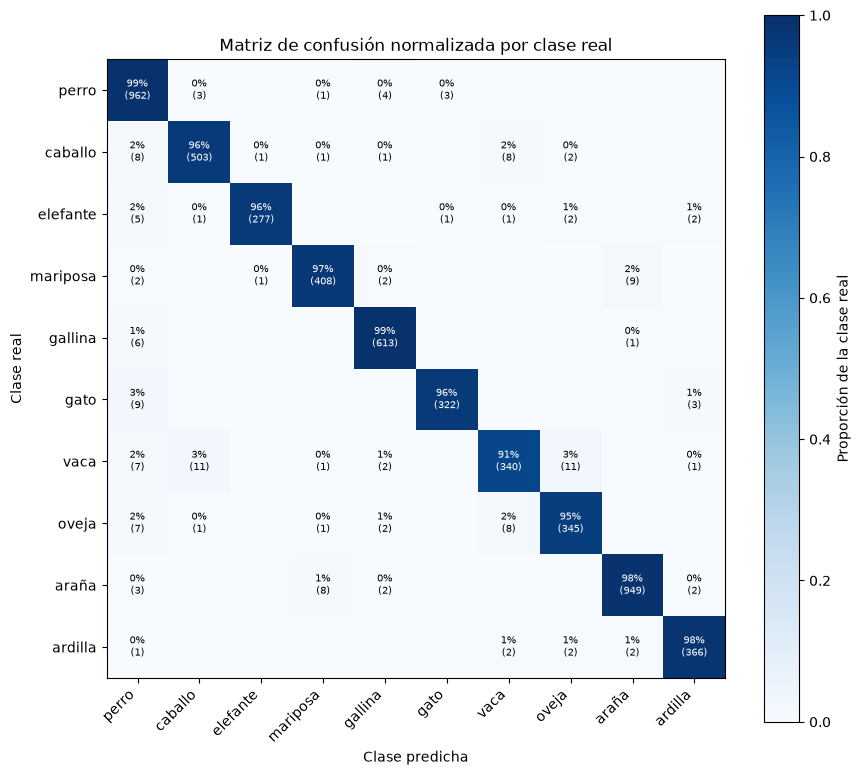

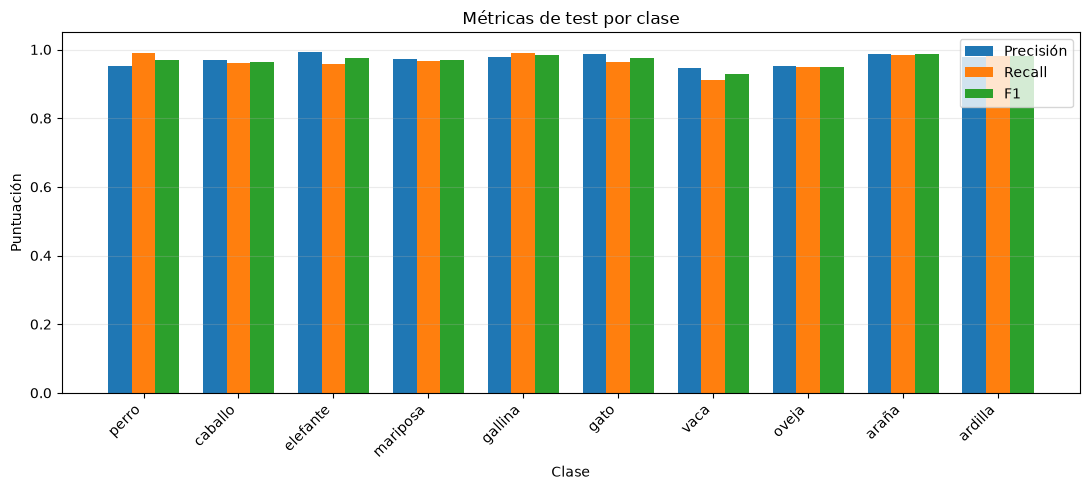

In [23]:
from sklearn.metrics import classification_report, confusion_matrix

predicted_test = test_predictions['predicted_class'].to_numpy()
report = classification_report(
    y_test, predicted_test, labels=CLASS_NAMES,
    target_names=[CLASS_NAMES_ES[name] for name in CLASS_NAMES],
    output_dict=True, zero_division=0)
test_metrics = {
    'model': 'svm_rbf', 'test_rows': len(y_test),
    'accuracy': float(accuracy_score(y_test, predicted_test)),
    'macro_f1': float(f1_score(y_test, predicted_test, average='macro')),
    'weighted_f1': float(f1_score(y_test, predicted_test, average='weighted')),
    'per_class': report,
}
(ARTIFACTS_DIR / 'metricas_test.json').write_text(json.dumps(
    test_metrics, ensure_ascii=False, indent=2), encoding='utf-8')
per_class = pd.DataFrame(report).T.loc[[CLASS_NAMES_ES[name] for name in CLASS_NAMES],
                                    ['precision', 'recall', 'f1-score', 'support']]
display(per_class.round(4))
print(f'Accuracy={test_metrics["accuracy"]:.4f}; '      f'macro F1={test_metrics["macro_f1"]:.4f}; '      f'weighted F1={test_metrics["weighted_f1"]:.4f}')
confusion_counts = confusion_matrix(y_test, predicted_test, labels=CLASS_NAMES)
confusion_normalized = confusion_matrix(
    y_test, predicted_test, labels=CLASS_NAMES, normalize='true')
pd.DataFrame(confusion_counts, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    ARTIFACTS_DIR / 'matriz_confusion_conteos.csv')
pd.DataFrame(confusion_normalized, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    ARTIFACTS_DIR / 'matriz_confusion_normalizada.csv')

fig, axis = plt.subplots(figsize=(9, 8))
image_matrix = axis.imshow(confusion_normalized, cmap='Blues', vmin=0, vmax=1)
names_es = [CLASS_NAMES_ES[name] for name in CLASS_NAMES]
axis.set_xticks(range(10), names_es, rotation=45, ha='right')
axis.set_yticks(range(10), names_es)
axis.set(xlabel='Clase predicha', ylabel='Clase real',
         title='Matriz de confusión normalizada por clase real')
for row in range(10):
    for col in range(10):
        if confusion_counts[row, col]:
            axis.text(col, row, f'{confusion_normalized[row, col]:.0%}\n({confusion_counts[row, col]})',
                      ha='center', va='center', fontsize=7,
                      color='white' if confusion_normalized[row, col] > 0.5 else 'black')
fig.colorbar(image_matrix, ax=axis, label='Proporción de la clase real')
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_matriz_confusion_test.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axis = plt.subplots(figsize=(11, 5))
positions = np.arange(10)
for offset, field, label in ((-0.25, 'precision', 'Precisión'),
                             (0, 'recall', 'Recall'),
                             (0.25, 'f1-score', 'F1')):
    axis.bar(positions + offset, per_class[field], width=0.25, label=label)
axis.set_xticks(positions, names_es, rotation=45, ha='right')
axis.set(ylim=(0, 1.05), xlabel='Clase', ylabel='Puntuación',
         title='Métricas de test por clase')
axis.legend()
axis.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_metricas_por_clase.png', dpi=180, bbox_inches='tight')
plt.show()

### t-SNE de desarrollo

Se toma una muestra estratificada de hasta 150 embeddings por clase de desarrollo. PCA reduce primero a 50 dimensiones y t-SNE proyecta a dos dimensiones (`perplexity=30`, `max_iter=1000`, `init='pca'`, semilla 42). Los grupos y solapamientos ayudan a explorar las representaciones, pero las distancias globales y el tamaño de los grupos en el plano no son medidas exactas de separación entre clases.

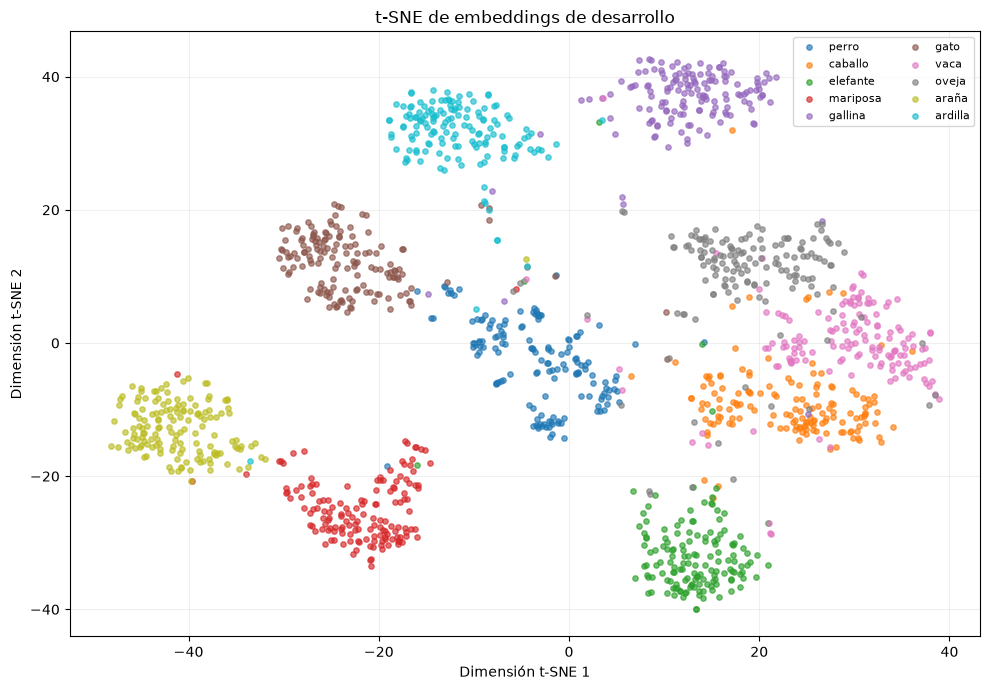

t-SNE: 1500 puntos; KL final=0.898


In [24]:
from sklearn.manifold import TSNE

rng_tsne = np.random.default_rng(SEED + 1)
tsne_indices = np.concatenate([
    rng_tsne.choice(np.flatnonzero(y_development == name),
                    size=min(150, int((y_development == name).sum())), replace=False)
    for name in CLASS_NAMES
])
tsne_vectors = np.asarray(X_development[tsne_indices], dtype=np.float32)
pca_50 = PCA(n_components=50, svd_solver='randomized', random_state=SEED)
tsne_input = pca_50.fit_transform(tsne_vectors)
tsne = TSNE(n_components=2, perplexity=30, learning_rate='auto',
            init='pca', max_iter=1000, random_state=SEED)
tsne_coordinates = tsne.fit_transform(tsne_input)
tsne_table = labels_development.iloc[tsne_indices][
    ['relative_path', 'class_name', 'class_es']].copy()
tsne_table['tsne_1'] = tsne_coordinates[:, 0]
tsne_table['tsne_2'] = tsne_coordinates[:, 1]
tsne_table.to_csv(ARTIFACTS_DIR / 'proyeccion_tsne_desarrollo.csv', index=False)
fig, axis = plt.subplots(figsize=(10, 7))
for index, name in enumerate(CLASS_NAMES):
    points = tsne_table[tsne_table['class_name'] == name]
    axis.scatter(points['tsne_1'], points['tsne_2'],
                 s=15, alpha=0.65, color=plt.get_cmap('tab10').colors[index],
                 label=CLASS_NAMES_ES[name])
axis.set(title='t-SNE de embeddings de desarrollo',
         xlabel='Dimensión t-SNE 1', ylabel='Dimensión t-SNE 2')
axis.legend(ncol=2, fontsize=8)
axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_tsne_desarrollo.png', dpi=180, bbox_inches='tight')
plt.show()
print(f't-SNE: {len(tsne_table)} puntos; KL final={tsne.kl_divergence_:.3f}')

### Ejemplos y confusiones frecuentes

Se muestran cuatro aciertos y cuatro errores con la mayor brecha entre las dos puntuaciones de decisión superiores. Esta brecha solo ayuda a ordenar casos de inspección; **no es una probabilidad**. La tabla de pares de confusión se calcula con conteos reales de test.

,true_class,predicted_class,count,fraction_of_true_class
0,vaca,caballo,11,0.029491
1,vaca,oveja,11,0.029491
2,gato,perro,9,0.026946
3,mariposa,araña,9,0.021327
4,caballo,perro,8,0.015267
5,araña,mariposa,8,0.008299
6,oveja,vaca,8,0.021978
7,caballo,vaca,8,0.015267
8,oveja,perro,7,0.019231
9,vaca,perro,7,0.018767


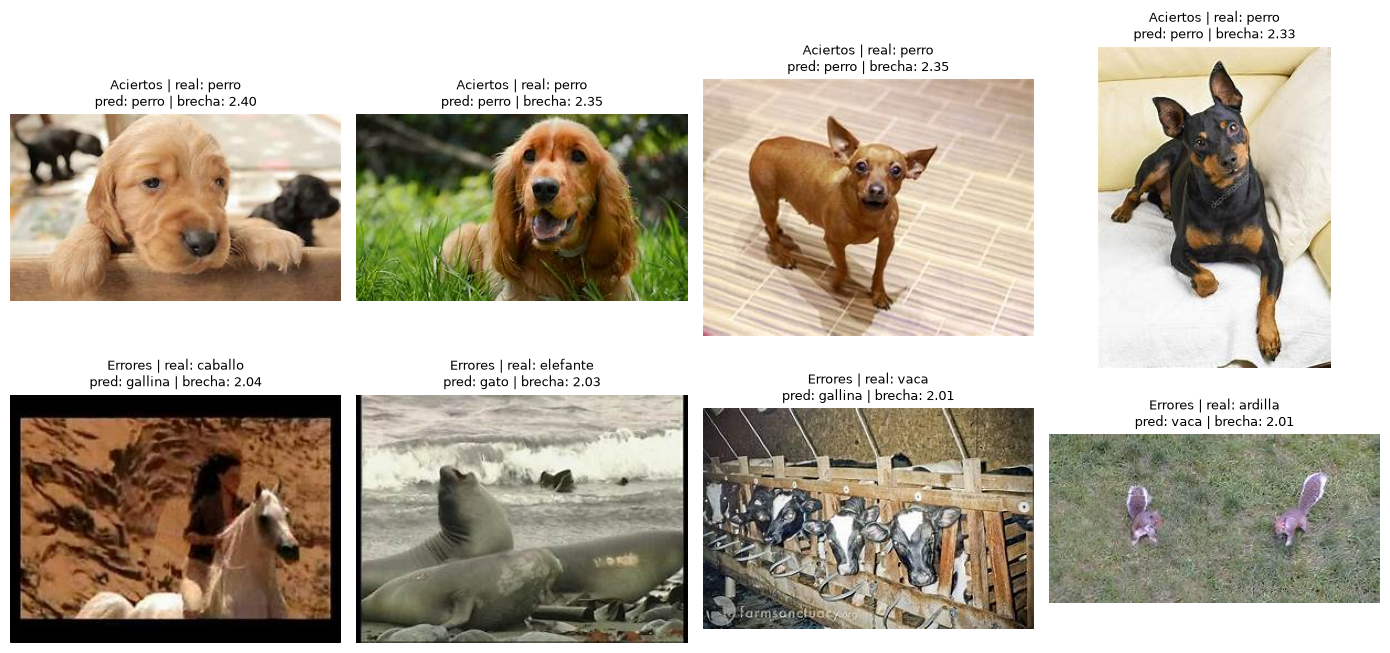

In [25]:
confusion_pairs = []
for row, true_name in enumerate(CLASS_NAMES):
    for col, predicted_name in enumerate(CLASS_NAMES):
        if row != col and confusion_counts[row, col] > 0:
            confusion_pairs.append({
                'true_class': CLASS_NAMES_ES[true_name],
                'predicted_class': CLASS_NAMES_ES[predicted_name],
                'count': int(confusion_counts[row, col]),
                'fraction_of_true_class': float(confusion_normalized[row, col]),
            })
confusion_pairs_table = pd.DataFrame(confusion_pairs).sort_values(
    'count', ascending=False).reset_index(drop=True)
confusion_pairs_table.to_csv(ARTIFACTS_DIR / 'pares_confusion_test.csv', index=False)
display(confusion_pairs_table.head(10))

top_correct = test_predictions[test_predictions['correct']].nlargest(
    4, 'score_gap_top2')
top_errors = test_predictions[~test_predictions['correct']].nlargest(
    4, 'score_gap_top2')
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row_index, (title, rows) in enumerate((
        ('Aciertos', top_correct), ('Errores', top_errors))):
    for col_index, (_, item) in enumerate(rows.iterrows()):
        with Image.open(PROJECT_ROOT / item['relative_path']) as image:
            axes[row_index, col_index].imshow(
                ImageOps.exif_transpose(image).convert('RGB'))
        axes[row_index, col_index].set_title(
            f'{title} | real: {item["true_class_es"]}\n'
            f'pred: {item["predicted_class_es"]} | brecha: {item["score_gap_top2"]:.2f}',
            fontsize=9)
        axes[row_index, col_index].axis('off')
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / 'figura_ejemplos_test.png', dpi=180, bbox_inches='tight')
plt.show()

**Estado:** la etapa 6 termina con métricas de test, matriz de confusión, t-SNE y ejemplos de errores. La etapa 7 sintetizará los resultados observados, las limitaciones, referencias y pasos de reproducción.

### Ajuste final complementario de regresión logística

La propuesta prevé reentrenar ambos modelos con todo desarrollo. Se ajusta aquí la regresión logística con los hiperparámetros fijados en la etapa 4 y se conserva su pipeline. Esta celda **no predice test**: la comparación entre modelos ya quedó establecida en la etapa 5 y la evaluación única del test corresponde a la SVM seleccionada.


In [26]:
from pathlib import Path
import hashlib
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

artifacts_logistic = Path.cwd().resolve() / 'artifacts'
config_bytes_logistic = (artifacts_logistic / 'configuracion_modelos.json').read_bytes()
config_logistic = json.loads(config_bytes_logistic)
X_logistic_final = np.load(artifacts_logistic / 'embeddings_desarrollo.npy', mmap_mode='r')
y_logistic_final = pd.read_csv(artifacts_logistic / 'etiquetas_desarrollo.csv')['class_name'].to_numpy()
assert len(X_logistic_final) == len(y_logistic_final) == 20941
logistic_final = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        C=config_logistic['logistic']['classifier__C'],
        class_weight=config_logistic['logistic']['classifier__class_weight'],
        solver='lbfgs', max_iter=1000, random_state=42)),
])
logistic_final.fit(X_logistic_final, y_logistic_final)
model_logistic_path = artifacts_logistic / 'modelo_final_logistico.joblib'
joblib.dump(logistic_final, model_logistic_path)
meta_logistic = {
    'model': 'logistic_regression',
    'training_rows': len(y_logistic_final),
    'config_sha256': hashlib.sha256(config_bytes_logistic).hexdigest(),
    'manifest_sha256': config_logistic['design']['manifest_sha256'],
    'test_predictions': False,
}
(artifacts_logistic / 'modelo_final_logistico_meta.json').write_text(
    json.dumps(meta_logistic, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Regresión logística ajustada con {len(y_logistic_final):,} imágenes de desarrollo; modelo guardado.')


Regresión logística ajustada con 20,941 imágenes de desarrollo; modelo guardado.


## Etapa 7. Conclusiones y revisión

La pregunta de investigación se respondió con una comparación pareada en una parte de desarrollo que no participó en la búsqueda. La SVM RBF superó a la regresión logística en los diez folds: diferencia media **+0,00642 macro F1**, prueba t corregida **p = 0,01075** e intervalo aproximado del 95 % **[+0,00189; +0,01095]**. A nivel 0,05 se rechaza la igualdad media bajo este procedimiento. El intervalo incluye mejoras menores que el margen práctico predefinido de 0,005, así que la magnitud práctica mínima conserva incertidumbre.

Tras fijar la SVM, se ajustó con todo desarrollo y se evaluó una vez en el test reservado: **accuracy 0,9712; macro F1 0,9684; weighted F1 0,9711** sobre 5 236 imágenes. La clase más difícil fue vaca (F1 0,9290), con confusiones frecuentes con caballo y oveja. La dispersión t-SNE ayuda a explorar los embeddings, pero no mide rendimiento. Algunos errores de alta puntuación sugieren posibles etiquetas equivocadas; deben revisarse manualmente antes de corregir el dataset.

El resultado se limita a Animals-10 y a MobileNetV2 congelado. La búsqueda de parámetros se realizó con una submuestra por costo computacional. La partición por grupos reduce la fuga de imágenes duplicadas o muy parecidas detectadas, sin asegurar independencia perfecta frente a relaciones no detectadas. Para estudiar generalización fuera del conjunto se necesitan datos externos y una nueva evaluación predefinida.


### Comprobación final reproducible

La siguiente celda lee los resultados guardados, comprueba que las predicciones cubran exactamente las rutas de test y que los grupos de test y desarrollo no se mezclen. No vuelve a ajustar modelos ni a modificar el test. Los gráficos y las tablas detalladas están en `artifacts/`; `README.md` explica cómo generar esa carpeta desde cero.


In [27]:
from pathlib import Path
import json
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

root_review = Path.cwd().resolve()
artifacts_review = root_review / 'artifacts'
manifest_review = pd.read_csv(artifacts_review / 'particion.csv')
predictions_review = pd.read_csv(artifacts_review / 'predicciones_test.csv')
metrics_review = json.loads((artifacts_review / 'metricas_test.json').read_text(encoding='utf-8'))
inference_review = json.loads((artifacts_review / 'resumen_inferencia.json').read_text(encoding='utf-8'))
test_review = manifest_review.loc[manifest_review['split'] == 'test']
development_review = manifest_review.loc[manifest_review['split'] == 'development']
assert len(predictions_review) == len(test_review) == metrics_review['test_rows'] == 5236
assert predictions_review['relative_path'].is_unique
assert set(predictions_review['relative_path']) == set(test_review['relative_path'])
assert set(test_review['group_id']).isdisjoint(set(development_review['group_id']))
assert abs(accuracy_score(predictions_review['true_class'], predictions_review['predicted_class']) - metrics_review['accuracy']) < 1e-12
assert abs(f1_score(predictions_review['true_class'], predictions_review['predicted_class'], average='macro') - metrics_review['macro_f1']) < 1e-12
print(f"Test: {len(test_review):,} imágenes; accuracy={metrics_review['accuracy']:.4f}; macro F1={metrics_review['macro_f1']:.4f}")
print('Cobertura de rutas y separación de grupos: correctas')
print('Modelo seleccionado:', metrics_review['model'])


Test: 5,236 imágenes; accuracy=0.9712; macro F1=0.9684
Cobertura de rutas y separación de grupos: correctas
Modelo seleccionado: svm_rbf


### Referencias

[1] A. Corrado, [“Animals-10”](https://www.kaggle.com/datasets/alessiocorrado99/animals10), Kaggle. [En línea]. Disponible en: https://www.kaggle.com/datasets/alessiocorrado99/animals10.  
[2] M. Sandler, A. Howard, M. Zhu, A. Zhmoginov y L.-C. Chen, [“MobileNetV2: Inverted Residuals and Linear Bottlenecks”](https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html), en *Proc. IEEE/CVF CVPR*, 2018, pp. 4510–4520.  
[3] J. Deng et al., [“ImageNet: A Large-Scale Hierarchical Image Database”](https://image-net.org/static_files/papers/imagenet_cvpr09.pdf), en *Proc. IEEE CVPR*, 2009, pp. 248–255.  
[4] F. Pedregosa et al., [“Scikit-learn: Machine Learning in Python”](https://jmlr.org/papers/v12/pedregosa11a.html), *JMLR*, vol. 12, pp. 2825–2830, 2011.  
[5] C. Nadeau y Y. Bengio, [“Inference for the Generalization Error”](https://link.springer.com/article/10.1023/A:1024068626366), *Machine Learning*, vol. 52, pp. 239–281, 2003, doi: 10.1023/A:1024068626366.  
[6] L. van der Maaten y G. Hinton, [“Visualizing Data using t-SNE”](https://jmlr.org/papers/v9/vandermaaten08a.html), *JMLR*, vol. 9, pp. 2579–2605, 2008.

**Asistencia de IA.** Se utilizó un asistente para organizar las etapas, redactar explicaciones y desarrollar el código y los gráficos a solicitud del usuario. Las salidas numéricas proceden de la ejecución local del notebook y las comprobaciones reproducibles anteriores. La inspección visual de posibles etiquetas erróneas es orientativa y requiere confirmación humana.


**Indicaciones de IA registradas:**

- Etapas y documentación: “construir un notebook etapa por etapa, pedir autorización para iniciar cada etapa, generar explicaciones en archivo MD”.
- Figuras: “Quisiera que se generen graficos de analisis, dispersión comparacion para: Etapa 3 y 4 segun corresponda”.
- Cierre: “Una vez que termine ejecutar todas las erapas faltantes”.
